In [1]:
##################
### Keagan Moo ###
### 2026/02/20 ###
### Motif Stat ###
##################

suppressPackageStartupMessages({library(tidyverse)
library(matrixStats)
library(dplyr)
library(ggrepel)
#library(optparse)
library(glue)
library(data.table)
library(tidyverse)
library(tidyr)
library(ggplot2)
library(hash)
library(RColorBrewer)
library(pheatmap)
library("ggpattern")
library(GenomicRanges)
library(grid)
                               })

Warning message:
“package ‘ggpattern’ was built under R version 4.4.3”


In [2]:
# Poterntially Iterate through possible cell types in future
Types <- c(
  "Type_1",
  "Type_2a",
  "Type_2x",
  "Endothelial",
  "Mesenchymal_Stem_Cell")
cDex <- "Type_2a"

In [3]:
# Load in background
    # Metadata produced the same way as kgmoo_linear.R
    message("Loading metadata")
    metadata.factors <- readRDS("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts/metadata.factors")
    peaks_dir <- file.path("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/",
                           "arushivData20220415/fusion_150_ccc")
    message("Loading background peaks")
    peaks <- file.path(peaks_dir, glue("atac.{cDex}.ccc.tsv")) %>%
      fread(data.table = F) %>%
      tibble::column_to_rownames("feature") %>%
      data.matrix()
    
    peaks <- peaks[, colnames(peaks) != "V1"]
    
    # Put everything in the same order and remove samples with missing age
    peaks <- peaks[,colnames(peaks) %in% rownames(metadata.factors)]
    metadata.factors <- metadata.factors[metadata.factors$sample %in% colnames(peaks),]
    peaks <- peaks[,rownames(metadata.factors)]
    peaksBed <- rownames(peaks)
    peaksBedDF <- t(data.frame(strsplit(peaksBed, split = ":")))
    rownames(peaksBedDF) <- NULL
    colnames(peaksBedDF) <- NULL

Loading metadata

Loading background peaks

Warning message in fread(., data.table = F):
“Detected 286 column names but the data has 287 columns (i.e. invalid file). Added 1 extra default column name for the first column which is guessed to be row names or an index. Use setnames() afterwards if this guess is not correct, or fix the file write command that created the file to create a valid file.”


In [4]:
##############################################################
### RUN BED TOOLS COMMMANDS in bed2tsv file in this folder ### <- CONCERN: 149,751 peaks turns into 211,495
############################################################## <- with duplicated peaks identified

In [4]:
pListTFs <- data.frame(data = list.files(path = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/chromatinTFAll/ref/"))
pListTFs$data <- substr(pListTFs$data,1,nchar(pListTFs$data)-4)
pListTFs$data <- gsub("::", "_and_", pListTFs$data)
pListTFs$data <- gsub("-", "_dash_", pListTFs$data)
pListTFs <- pListTFs$data
combinedModels <- data.frame(matrix(0, 2, 6))
colnames(combinedModels) <- c("F GLM", "M GLM", 
                "F GLM UP", "M GLM UP", "F GLM DOWN", "M GLM DOWN")
rownames(combinedModels) <- c("Test Coef", "Test PNom")

In [ ]:
length(pListTFs)

[1] "AFP_1"                    "AHR_1"                   
   [3] "AHR_2"                    "AHR_and_ARNT_1"          
   [5] "AHR_and_ARNT_2"           "AHR_and_ARNT_and_HIF1A_1"
   [7] "AIRE_1"                   "AIRE_2"                  
   [9] "ALX1_1"                   "ALX1_2"                  
  [11] "ALX1_3"                   "ALX1_4"                  
  [13] "ALX1_5"                   "ALX1_6"                  
  [15] "ALX3_1"                   "ALX3_2"                  
  [17] "ALX3_3"                   "ALX3_4"                  
  [19] "ALX4_1"                   "ALX4_2"                  
  [21] "ALX4_3"                   "ALX4_4"                  
  [23] "AP1_disc1"                "AP1_disc10"              
  [25] "AP1_disc2"                "AP1_disc3"               
  [27] "AP1_disc4"                "AP1_disc5"               
  [29] "AP1_disc6"                "AP1_disc7"               
  [31] "AP1_disc8"                "AP1_disc9"               
  [33] "AP1_known1"               "AP1_known10"             
  [35] "AP1_known2"               "AP1_known3"              
  [37] "AP1_known4"               "AP1_known5"              
  [39] "AP1_known6"               "AP1_known7"              
  [41] "AP1_known8"               "AP1_known9"              
  [43] "AP3_1"                    "ARHGEF12_1"              
  [45] "ARID3A_2"                 "ARID5A_1"                
  [47] "ARID5B_1"                 "ARNT_1"                  
  [49] "ARNT_2"                   "ARNTL_1"                 
  [51] "ARX_1"                    "ARX_2"                   
  [53] "ARX_3"                    "ASCL2_1"                 
  [55] "ASCL2_2"                  "ATF2_1"                  
  [57] "ATF2_2"                   "ATF2_3"                  
  [59] "ATF3_disc1"               "ATF3_disc2"              
  [61] "ATF3_disc3"               "ATF3_disc4"              
  [63] "ATF3_known1"              "ATF3_known10"            
  [65] "ATF3_known12"             "ATF3_known13"            
  [67] "ATF3_known14"             "ATF3_known15"            
  [69] "ATF3_known16"             "ATF3_known2"             
  [71] "ATF3_known3"              "ATF3_known4"             
  [73] "ATF3_known5"              "ATF3_known6"             
  [75] "ATF3_known7"              "ATF3_known8"             
  [77] "ATF3_known9"              "ATF4_1"                  
  [79] "ATF4_2"                   "ATF4_3"                  
  [81] "ATF6_1"                   "ATF7_1"                  
  [83] "ATOH1_1"                  "BACH1_1"                 
  [85] "BACH2_1"                  "BARHL1_1"                
  [87] "BARHL1_2"                 "BARHL1_3"                
  [89] "BARHL1_4"                 "BARHL2_1"                
  [91] "BARHL2_2"                 "BARHL2_3"                
  [93] "BARHL2_4"                 "BARHL2_5"                
  [95] "BARHL2_6"                 "BARHL2_7"                
  [97] "BARX1_1"                  "BARX1_2"                 
  [99] "BARX1_3"                  "BARX2_1"                 
 [101] "BATF_disc1"               "BATF_disc2"              
 [103] "BATF_disc3"               "BATF_known1"             
 [105] "BBX_1"                    "BCL_disc1"               
 [107] "BCL_disc10"               "BCL_disc2"               
 [109] "BCL_disc3"                "BCL_disc4"               
 [111] "BCL_disc5"                "BCL_disc6"               
 [113] "BCL_disc7"                "BCL_disc8"               
 [115] "BCL_disc9"                "BCL6B_1"                 
 [117] "BCL6B_2"                  "BDP1_disc1"              
 [119] "BDP1_disc2"               "BDP1_disc3"              
 [121] "BHLHA15_1"                "BHLHE22_1"               
 [123] "BHLHE23_1"                "BHLHE40_disc1"           
 [125] "BHLHE40_disc2"            "BHLHE40_known1"          
 [127] "BHLHE40_known2"           "BHLHE40_known3"          
 [129] "BHLHE40_known4"           "BHLHE41_1"               
 [131] "BHLHE41_2"                "BPT

In [5]:
peaksEns <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/{cDex}_bgoEns.tsv"), sep = "\t")[,c("V1", "V2", "V3", "V10")]
colnames(peaksEns) <- c("peak_chromosome", "peak_startPosition", "peak_endPosition", "Distance")
peaksEns$Distance <- abs(peaksEns$Distance)
peaksEns <- peaksEns %>% distinct(peak_chromosome, peak_startPosition, peak_endPosition, Distance, .keep_all=TRUE)

# Load GLMNB peaks
#GLMNBSelected <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/Summary"))
GLMNBSelectedF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_{cDex}.tsv"), sep = "\t", header = TRUE)
#write.csv(fCCluster_Linear_nom, file =glue("/lab/work/kgmoo/ARIMAke/albanusScripts/KMOutCCC/linear_per_cluster/{Type}_glmoff_female.csv"))
GLMNBSelectedM <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_{cDex}.tsv"), sep = "\t", header = TRUE)
#write.csv(mCCluster_Linear_nom, file =glue("/lab/work/kgmoo/ARIMAke/albanusScripts/KMOutCCC/linear_per_cluster/{Type}_glmoff_male.csv"))

fComp <- GLMNBSelectedF %>% dplyr::select("estimate", "p_FDR") %>% dplyr::filter(p_FDR < 0.05)
fCompUP <- fComp %>% dplyr::filter (estimate > 0)
fCompDOWN <- fComp %>% dplyr::filter (estimate < 0)
mComp <- GLMNBSelectedM %>% dplyr::select("estimate", "p_FDR") %>% dplyr::filter(p_FDR < 0.05)
mCompUP <- mComp %>% dplyr::filter (estimate > 0)
mCompDOWN <- mComp %>% dplyr::filter (estimate < 0)

fSelectGLM <- data.frame(Select = rownames(fComp))
fSelectGLMUP <- data.frame(Select = rownames(fCompUP))
fSelectGLMDOWN <- data.frame(Select = rownames(fCompDOWN))
mSelectGLM <- data.frame(Select = rownames(mComp))
mSelectGLMUP <- data.frame(Select = rownames(mCompUP))
mSelectGLMDOWN <- data.frame(Select = rownames(mCompDOWN))
fpeaksSelectedGLM <- unique(fSelectGLM$Select)
fpeaksSelectedGLMUP <- unique(fSelectGLMUP$Select)
fpeaksSelectedGLMDOWN <- unique(fSelectGLMDOWN$Select)
mpeaksSelectedGLM <- unique(mSelectGLM$Select)
mpeaksSelectedGLMUP <- unique(mSelectGLMUP$Select)
mpeaksSelectedGLMDOWN <- unique(mSelectGLMDOWN$Select)

AgePeaks <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Res/ChromEnrich/AgePeaks_{cDex}_GLMMNB_05.rds"))

nucData <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/{cDex}_Nuc.tsv"), sep = "\t")
colnames(nucData) <- c("chr", "start", "end", "ATp", "GCp", "Act", "Cct", "Gct", "Tct", "Nct", "Otherct", "Total_Length")
nucData$peaKey <- paste(nucData$chr, nucData$start, 
                        nucData$end, sep=":")
GCData <- nucData %>% dplyr::select(c("peaKey", "GCp"))

In [8]:
head(GLMNBSelectedF)
head(AgePeaks)
head(GCData)
pListTFs

,index,group_i,estimate,se,z,p_GLMMNB,p_LRT,p_FDR
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr2:11498628:11498929,chr2:11498628:11498929,age,-0.01963274,0.003024427,-6.491390,8.504790e-11,1.350284e-09,2.812736e-05
chr11:8707647:8707948,chr11:8707647:8707948,age,-0.02680207,0.004068735,-6.587323,4.478268e-11,2.002974e-09,2.812736e-05
chr2:99636680:99636981,chr2:99636680:99636981,age,-0.02017123,0.003107073,-6.492037,8.468336e-11,2.058451e-09,2.812736e-05
chr11:45161832:45162133,chr11:45161832:45162133,age,-0.01778280,0.002801943,-6.346595,2.201331e-10,5.618086e-09,5.051857e-05
chr5:9529007:9529308,chr5:9529007:9529308,age,-0.03063259,0.004986049,-6.143661,8.064102e-10,6.420021e-09,5.051857e-05
chr11:8810544:8810845,chr11:8810544:8810845,age,-0.02053505,0.003317511,-6.189896,6.020402e-10,7.394223e-09,5.051857e-05


[1] "chr11:72722468:72722769"   "chr3:42880982:42881283"   
[3] "chr17:40417867:40418168"   "chr20:50399288:50399589"  
[5] "chr10:124699977:124700278" "chr3:66450696:66450997"

,peaKey,GCp
,<chr>,<dbl>
1,chr1:181326:181627,0.737542
2,chr1:184374:184675,0.544850
3,chr1:191340:191641,0.604651
4,chr1:267853:268154,0.501661
5,chr1:586001:586302,0.514950
6,chr1:778582:778883,0.661130


[1] "AFP_1"                    "AHR_1"                   
   [3] "AHR_2"                    "AHR_and_ARNT_1"          
   [5] "AHR_and_ARNT_2"           "AHR_and_ARNT_and_HIF1A_1"
   [7] "AIRE_1"                   "AIRE_2"                  
   [9] "ALX1_1"                   "ALX1_2"                  
  [11] "ALX1_3"                   "ALX1_4"                  
  [13] "ALX1_5"                   "ALX1_6"                  
  [15] "ALX3_1"                   "ALX3_2"                  
  [17] "ALX3_3"                   "ALX3_4"                  
  [19] "ALX4_1"                   "ALX4_2"                  
  [21] "ALX4_3"                   "ALX4_4"                  
  [23] "AP1_disc1"                "AP1_disc10"              
  [25] "AP1_disc2"                "AP1_disc3"               
  [27] "AP1_disc4"                "AP1_disc5"               
  [29] "AP1_disc6"                "AP1_disc7"               
  [31] "AP1_disc8"                "AP1_disc9"               
  [33] "AP1_known1"               "AP1_known10"             
  [35] "AP1_known2"               "AP1_known3"              
  [37] "AP1_known4"               "AP1_known5"              
  [39] "AP1_known6"               "AP1_known7"              
  [41] "AP1_known8"               "AP1_known9"              
  [43] "AP3_1"                    "ARHGEF12_1"              
  [45] "ARID3A_2"                 "ARID5A_1"                
  [47] "ARID5B_1"                 "ARNT_1"                  
  [49] "ARNT_2"                   "ARNTL_1"                 
  [51] "ARX_1"                    "ARX_2"                   
  [53] "ARX_3"                    "ASCL2_1"                 
  [55] "ASCL2_2"                  "ATF2_1"                  
  [57] "ATF2_2"                   "ATF2_3"                  
  [59] "ATF3_disc1"               "ATF3_disc2"              
  [61] "ATF3_disc3"               "ATF3_disc4"              
  [63] "ATF3_known1"              "ATF3_known10"            
  [65] "ATF3_known12"             "ATF3_known13"            
  [67] "ATF3_known14"             "ATF3_known15"            
  [69] "ATF3_known16"             "ATF3_known2"             
  [71] "ATF3_known3"              "ATF3_known4"             
  [73] "ATF3_known5"              "ATF3_known6"             
  [75] "ATF3_known7"              "ATF3_known8"             
  [77] "ATF3_known9"              "ATF4_1"                  
  [79] "ATF4_2"                   "ATF4_3"                  
  [81] "ATF6_1"                   "ATF7_1"                  
  [83] "ATOH1_1"                  "BACH1_1"                 
  [85] "BACH2_1"                  "BARHL1_1"                
  [87] "BARHL1_2"                 "BARHL1_3"                
  [89] "BARHL1_4"                 "BARHL2_1"                
  [91] "BARHL2_2"                 "BARHL2_3"                
  [93] "BARHL2_4"                 "BARHL2_5"                
  [95] "BARHL2_6"                 "BARHL2_7"                
  [97] "BARX1_1"                  "BARX1_2"                 
  [99] "BARX1_3"                  "BARX2_1"                 
 [101] "BATF_disc1"               "BATF_disc2"              
 [103] "BATF_disc3"               "BATF_known1"             
 [105] "BBX_1"                    "BCL_disc1"               
 [107] "BCL_disc10"               "BCL_disc2"               
 [109] "BCL_disc3"                "BCL_disc4"               
 [111] "BCL_disc5"                "BCL_disc6"               
 [113] "BCL_disc7"                "BCL_disc8"               
 [115] "BCL_disc9"                "BCL6B_1"                 
 [117] "BCL6B_2"                  "BDP1_disc1"              
 [119] "BDP1_disc2"               "BDP1_disc3"              
 [121] "BHLHA15_1"                "BHLHE22_1"               
 [123] "BHLHE23_1"                "BHLHE40_disc1"           
 [125] "BHLHE40_disc2"            "BHLHE40_known1"          
 [127] "BHLHE40_known2"           "BHLHE40_known3"          
 [129] "BHLHE40_known4"           "BHLHE41_1"               
 [131] "BHLHE41_2"                "BPT

In [9]:
removedVec <- c()
for (tempTF in c("NR3C1_known18")) {
    print(tempTF)
    colonTF <- gsub("_and_", "::", tempTF)
    colonTF <- gsub("_dash_", "-", colonTF)
    peaksDF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/chromatinTFAll/intersect/{cDex}_bgoChrom_{colonTF}.tsv"), sep = "\t")
    print(head(peaksDF, n = 3))
    if (ncol(peaksDF) == 9) {
    colnames(peaksDF) <- c("peak_chromosome", "peak_startPosition", "peak_endPosition", "tf_chromosome", "tf_startPosition", "tf_endPosition", "TF", "TF_affinity", "TF_strand")
    peaksDF$TF <- gsub("::", "_and_", peaksDF$TF)
    peaksDF$TF <- gsub("-", "_dash_", peaksDF$TF)
    peaksDF <- left_join(peaksDF, peaksEns, by=c("peak_chromosome", "peak_startPosition", "peak_endPosition"))
    libsizes <- colSums(peaks)
    peaksizes <- data.frame(peaKey=rownames(peaks), median=rowMedians(peaks))
    
    #print(head(peaksDF, n = 3))
    
    if (all(names(libsizes) == metadata.factors$sample)) {
        message("Adding library sizes to meta data")
        metadata.factors$libsize <- log2(unname(libsizes))
    } else {
        stop("Something wrong (2)")
    }
    
    peaKey <- paste(peaksDF$peak_chromosome, peaksDF$peak_startPosition, 
                peaksDF$peak_endPosition, sep=":")
    inputDF <- data.frame(peaKey)

    inputDF$fSelectedGLM <- as.integer(inputDF$peaKey %in% 
                                    fpeaksSelectedGLM)
    inputDF$mSelectedGLM <- as.integer(inputDF$peaKey %in% 
                                    mpeaksSelectedGLM)
    inputDF$fSelectedGLMUP <- as.integer(inputDF$peaKey %in% 
                                    fpeaksSelectedGLMUP)
    inputDF$mSelectedGLMUP <- as.integer(inputDF$peaKey %in% 
                                    mpeaksSelectedGLMUP)
    inputDF$fSelectedGLMDOWN <- as.integer(inputDF$peaKey %in% 
                                        fpeaksSelectedGLMDOWN)
    inputDF$mSelectedGLMDOWN <- as.integer(inputDF$peaKey %in% 
                                        mpeaksSelectedGLMDOWN)
    inputDF$Distal5kb <- as.integer(peaksDF$Distance > 5000)
    inputDF <- merge(inputDF, peaksizes, by = "peaKey")
    inputDF <- merge(inputDF, GCData, by = "peaKey")
    
    inputDF <- inputDF[!duplicated(inputDF), ]
    duPeaks <- inputDF[duplicated(inputDF$peaKey),]$peaKey
    
    #print(glue("Peaks going in = ", dim(inputDF)[1]))
    
    stateTerms <- peaksDF[peaksDF$TF != ".",c(7,1,2,3)]
    
    peaKollapse <- paste(stateTerms$peak_chromosome, stateTerms$peak_startPosition, 
                        stateTerms$peak_endPosition, sep=":")
    stateTerms$peakCoord <- peaKollapse
    statePeaks <- stateTerms[,c(1,5)]
    stateTerms <- statePeaks %>% group_by(TF) %>% summarise(peakCoord = list(peakCoord))
    
    FauxRaux <- c(0,1)
    setList <- c("F GLM", "M GLM", 
                "F GLM UP", "M GLM UP", "F GLM DOWN", "M GLM DOWN")
    models <- data.frame(replicate(length(setList), FauxRaux, simplify=FALSE))
    colnames(models) <- setList
    pListStateC <- paste0(tempTF, " Coef")
    pListStateP <- paste0(tempTF, " PNom")
    # Interleaves the strings and then sets them to row names
    rownames(models) <- c(rbind(pListStateC,pListStateP))
    
    tryModel <- function(FUNformula, FUNinput, ...) {
       tempModel <- tryCatch(
         expr = {
           tempModel <- glm(formula = FUNformula, family="binomial", data=FUNinput)
         }, 
         error = function(e){
           print(glue("{tempName} suffered a fatal error"))
           tempModel <- -1
         }, 
         warning = function(w){
           print(glue("{tempName} suffered a warning"))
           tempModel <- -1
         }, 
         finally = {
           #pass
         }) 
       return(tempModel)
    }
    
    for (sDex in 1:nrow(stateTerms)){
      
      tempName <- stateTerms[sDex,1]
      print(tempName)
      inputDF[glue("{tempName}")] <- as.integer(inputDF$peaKey %in% noquote(stateTerms$peakCoord[[sDex]]))
     
    }
    
    setSet <- c("fSelectedGLM", "mSelectedGLM", 
            "fSelectedGLMUP", "mSelectedGLMUP", 
            "fSelectedGLMDOWN", "mSelectedGLMDOWN")
    
    peakSetSet <- list(fpeaksSelectedGLM, mpeaksSelectedGLM,
                       fpeaksSelectedGLMUP, mpeaksSelectedGLMUP,
                       fpeaksSelectedGLMDOWN, mpeaksSelectedGLMDOWN)

    for (pDex in 1:length(setSet)) {
       tempPeak <- setSet[pDex]
       tempPeakSet <- peakSetSet[pDex]
       tempAgePeaks <- dplyr::setdiff(AgePeaks, tempPeakSet[[1]])
       tempInputDF <- inputDF[!(inputDF$peaKey %in% tempAgePeaks),]#
      
        tempForm <- as.formula(glue("{tempPeak}~median+Distal5kb+GCp+{tempTF}"))
        tempModel <- tryModel(FUNformula = tempForm, FUNinput = tempInputDF)
        if((typeof(tempModel) == "list")){
            models[2*sDex - 1, pDex] <- tempModel$coefficients[5]
            models[2*sDex, pDex] <- summary(tempModel)$coefficients[20]
        }
    }
    
    combinedModels <- rbind(combinedModels, models)
    } else {
        removedVec <- c(tempTF, removedVec)
        print("666666")
        print("666666")
        print("666666")
        print("666666")
        print("666666")
        print("666666")
    }
}

[1] "NR3C1_known18"
    V1     V2     V3 V4 V5 V6 V7 V8 V9
1 chr1 181326 181627  . -1 -1  . -1  .
2 chr1 184374 184675  . -1 -1  . -1  .
3 chr1 191340 191641  . -1 -1  . -1  .


Adding library sizes to meta data



# A tibble: 1 × 1
  TF           
  <chr>        
1 NR3C1_known18


In [10]:
tempModel


Call:  glm(formula = FUNformula, family = "binomial", data = FUNinput)

Coefficients:
  (Intercept)         median      Distal5kb            GCp  NR3C1_known18  
     -7.52609        0.01212        0.45779        3.73491        1.33293  

Degrees of Freedom: 124779 Total (i.e. Null);  124775 Residual
Null Deviance:	    10610 
Residual Deviance: 10020 	AIC: 10030

In [26]:
combinedModels[-(1:2),]

,F GLM,M GLM,F GLM UP,M GLM UP,F GLM DOWN,M GLM DOWN
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AHR_2 Coef,-0.367195148,-0.62548268,0.01705602,-0.45507125,-0.6250575039,-0.75471396
AHR_2 PNom,0.007753406,0.10204090,0.93038688,0.40657159,0.0008346737,0.15562380
AHR_and_ARNT_1 Coef,-0.197052335,-0.19660362,-0.12108537,-0.43843650,-0.2270971908,-0.04922114
AHR_and_ARNT_1 PNom,0.162132597,0.58104177,0.58896779,0.47219651,0.1914498718,0.91015251
AHR_and_ARNT_2 Coef,-0.170365369,-0.28644661,-0.05814676,-0.04829652,-0.2497845952,-0.46608362
AHR_and_ARNT_2 PNom,0.117751952,0.30868252,0.73723594,0.90728863,0.0653811603,0.22502004
AHR_and_ARNT_and_HIF1A_1 Coef,-0.293266541,-0.59087461,-0.02078673,0.03462237,-0.4557920852,-1.30617186
AHR_and_ARNT_and_HIF1A_1 PNom,0.017575024,0.08658952,0.91028415,0.93686150,0.0044301889,0.02990089


In [12]:
head(peaksDF[peaksDF$TF_affinity > 0 ,])
dim(inputDF)
head(inputDF[inputDF$fSelectedGLM == 1,])

,peak_chromosome,peak_startPosition,peak_endPosition,tf_chromosome,tf_startPosition,tf_endPosition,TF,TF_affinity,TF_strand,Distance
,<chr>,<int>,<int>,<chr>,<int>,<int>,<chr>,<dbl>,<chr>,<int>
2,chr1,181326,181627,chr1,181510,181519,AHR::ARNT::HIF1A_1,12.0748,-,1069
10,chr1,817195,817496,chr1,817455,817464,AHR::ARNT::HIF1A_1,11.2804,-,0
18,chr1,842726,843027,chr1,842950,842959,AHR::ARNT::HIF1A_1,11.1495,-,8321
27,chr1,869794,870095,chr1,869842,869851,AHR::ARNT::HIF1A_1,11.3084,-,106
28,chr1,869794,870095,chr1,869887,869896,AHR::ARNT::HIF1A_1,12.1215,-,106
35,chr1,904625,904926,chr1,904842,904851,AHR::ARNT::HIF1A_1,11.8598,+,0


[1] 171028     10

,peaKey,fSelectedGLM,mSelectedGLM,fSelectedGLMUP,mSelectedGLMUP,fSelectedGLMDOWN,mSelectedGLMDOWN,Distal5kb,median,GCp
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
42,chr1:10052390:10052691,1,0,0,0,1,0,0,31.5,0.461794
263,chr1:10710559:10710860,1,0,0,0,1,0,0,64.5,0.574751
264,chr1:10713655:10713956,1,0,0,0,1,0,1,37.0,0.578073
314,chr1:1080140:1080441,1,0,1,0,0,0,0,41.0,0.681063
317,chr1:108082023:108082324,1,0,0,0,1,0,1,65.5,0.544850
340,chr1:108559854:108560155,1,0,0,0,1,0,0,58.0,0.727575


In [11]:
dim(modelsDF)

[1]   6 472

In [7]:
  ### PART 3: Display and save the results
combinedModels <- combinedModels[-(1:2),]
modelsDF <- data.frame(t(combinedModels))
    for (nDex in 1:ncol(modelsDF)) {modelsDF[,nDex] <- as.numeric(modelsDF[,nDex])}
head(modelsDF)

,AFP_1.Coef,AFP_1.PNom,AHR_1.Coef,AHR_1.PNom,AHR_2.Coef,AHR_2.PNom,AHR_and_ARNT_1.Coef,AHR_and_ARNT_1.PNom,AHR_and_ARNT_2.Coef,AHR_and_ARNT_2.PNom,⋯,ZNF8_1.Coef,ZNF8_1.PNom,ZSCAN16_1.Coef,ZSCAN16_1.PNom,ZSCAN26_1.Coef,ZSCAN26_1.PNom,ZSCAN4_2.Coef,ZSCAN4_2.PNom,ZSCAN4_3.Coef,ZSCAN4_3.PNom
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
F GLM,1.1627676,0.27078728,0.29166288,0.5988144,-0.09403695,0.90416906,-0.7580603,0.46951320,-0.7338371,0.34751305,⋯,-14.04018296,0.9859402,-14.3778381,0.98540860,2.0801977,7.267550e-03,-14.51618857,0.9838412,1.02185486,0.05129938
M GLM,-0.3499028,0.44114900,-0.10635493,0.4944289,-0.39707951,0.07322156,-0.5235848,0.03288583,-0.3014961,0.08921817,⋯,0.02203599,0.9498490,0.2843398,0.19439544,-1.8338230,6.794271e-02,-0.00189476,0.9932844,0.13448536,0.42480987
F GLM UP,2.7219651,0.02468416,0.05344098,0.9633538,-14.59174970,0.99034445,-14.4926595,0.99047652,1.4575427,0.13920699,⋯,-13.43468233,0.9921649,-14.1134530,0.99122198,4.0017175,7.102603e-05,-14.23097376,0.9903686,0.60115107,0.59134607
M GLM UP,-0.5520675,0.58457789,0.13954702,0.5555453,0.03910413,0.89430436,-0.3357052,0.34122162,-0.1978720,0.45957125,⋯,-0.14106293,0.7986043,0.6313092,0.07518281,-0.5168123,6.102339e-01,-0.59814985,0.2451365,0.09242615,0.75898331
F GLM DOWN,-12.8069230,0.98609201,0.36689620,0.5624112,0.21340923,0.79153773,-0.4837310,0.64980098,-15.9637043,0.98550344,⋯,-13.81029248,0.9859891,-14.0409010,0.98578357,-12.9125899,9.874851e-01,-14.18646406,0.9842006,1.15867951,0.05196063
M GLM DOWN,-0.3025758,0.55182825,-0.27933859,0.1732010,-0.78179246,0.01990907,-0.6552691,0.04925027,-0.3691646,0.11007271,⋯,0.06344377,0.8832744,0.1166077,0.67493139,-13.9650039,9.637934e-01,0.19562402,0.4308037,0.15816627,0.43135908


In [15]:
#modelsDF$Active_TSS.PBonferroni <- p.adjust(modelsDF$Active_TSS.PNom, method = "bonferroni", n=nrow(modelsDF))

In [8]:
saveRDS(inputDF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                            {cDex}_TFEnrichmentInputDF_All_IndivMod_BGxGLM05_AGxGLM005.rds"))
saveRDS(modelsDF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                            {cDex}_TFEnrichmentModels_All_IndivMod_BGxGLM05_AGxGLM005.rds"))

,TF,peakSet,Coef,NomP
,<chr>,<chr>,<dbl>,<dbl>
2,AFP_1,F GLM,1.1627676,0.27078728
3,AFP_1,M GLM,-0.3499028,0.44114900
4,AFP_1,F GLM UP,2.7219651,0.02468416
5,AFP_1,M GLM UP,-0.5520675,0.58457789
6,AFP_1,F GLM DOWN,-12.8069230,0.98609201
7,AFP_1,M GLM DOWN,-0.3025758,0.55182825


[1] 3234    4

[1] 2.029088e-18

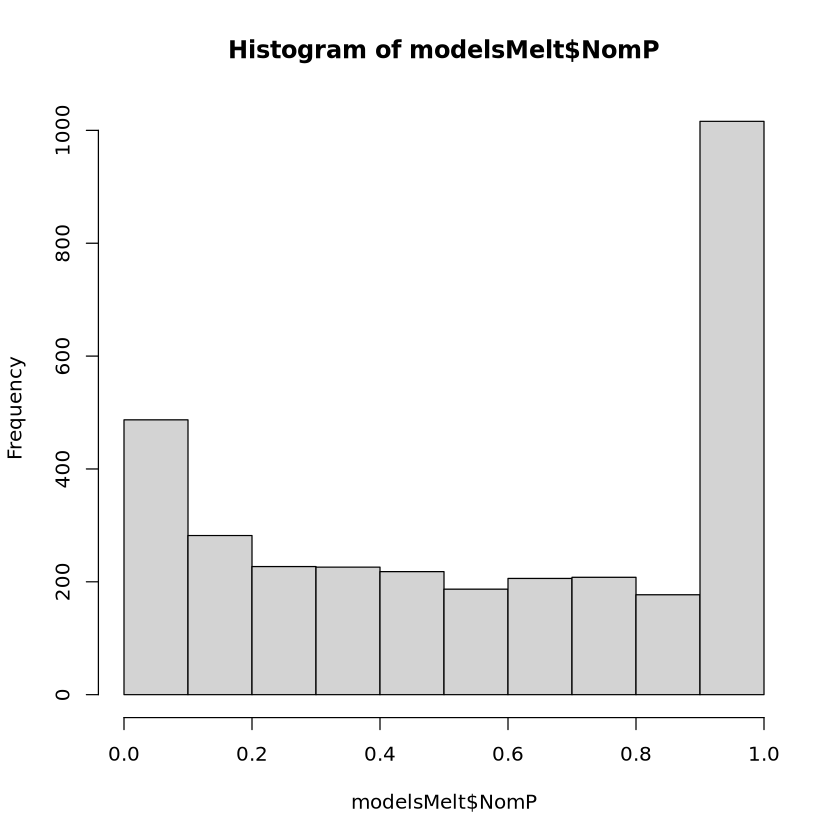

In [9]:
#MELT models for reading
    modelsCoef <- modelsDF %>% dplyr::select(contains("Coef"))
    modelsNom <- modelsDF %>% dplyr::select(contains("PNom"))
    modelsMelt <- data.frame(TF = -1, peakSet = -1, Coef = -1, NomP = -1)
    
    for(mDex in 1:ncol(modelsCoef)) {
      
      metaFrame <- data.frame(TF = rep(gsub(".Coef", "", colnames(modelsCoef)[mDex]), nrow(modelsDF)), peakSet = rownames(modelsCoef))
      metaFrame$Coef <- modelsCoef[,mDex]
      metaFrame$NomP <- modelsNom[,mDex]
      modelsMelt <- rbind(modelsMelt, metaFrame)
      
    }
    
    modelsMelt <- modelsMelt[-1,]
    head(modelsMelt)
    dim(modelsMelt)
    modelsMelt$BonP <- p.adjust(modelsMelt$NomP, method = "bonferroni", n=nrow(modelsMelt))
    min(modelsMelt$BonP)
    hist(modelsMelt$NomP)
    modelsMelt$Type <- glue("{cDex}")
    write.csv(modelsMelt, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                        {cDex}_TFEnrichmentModels_All_IndivMod_BGxGLM05_AGxGLM005.csv"), row.names = FALSE, quote = FALSE)

In [6]:
Type1 <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                        Type_1_TFEnrichmentModels_All3k_IndivMod_BGxGLM05_AGxGLM005.csv"))
Type2a <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                        Type_2a_TFEnrichmentModels_All3k_IndivMod_BGxGLM05_AGxGLM005.csv"))
Type2x <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                        Type_2x_TFEnrichmentModels_All3k_IndivMod_BGxGLM05_AGxGLM005.csv"))

Inter <- rbind(Type1, Type2a)
Final <- rbind(Inter, Type2x)
Final$Sex <- substr(Final$peakSet, 1, 1)
Final$Pattern <- c("Tot", "Tot", "Up", "Up", "Down", "Down")
write.csv(Final, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                Fiber_TFEnrichmentModels_All3k_IndivMod_BGxGLM05_AGxGLM005.csv"), row.names = FALSE, quote = FALSE)

TF,peakSet,Coef,NomP,BonP,Type
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
AFP_1,F GLM,0.04926699,0.8576096139,1,Type_2a
AFP_1,M GLM,-0.27418034,0.2309080650,1,Type_2a
AFP_1,F GLM UP,0.39762074,0.4438857413,1,Type_2a
AFP_1,M GLM UP,0.23810450,0.5203552490,1,Type_2a
AFP_1,F GLM DOWN,-0.06231451,0.8469930992,1,Type_2a
AFP_1,M GLM DOWN,-0.50003214,0.0877252377,1,Type_2a
AHR_1,F GLM,-0.09512706,0.3559179979,1,Type_2a
AHR_1,M GLM,-0.05981880,0.4376892819,1,Type_2a
AHR_1,F GLM UP,-0.06691337,0.7328916466,1,Type_2a


In [46]:
rep(c("Tot", "Tot", "Up", "Up", "Down", "Down"), 2)
head(Final, n = 12)
Final$TF

[1] "Tot"  "Tot"  "Up"   "Up"   "Down" "Down" "Tot"  "Tot"  "Up"   "Up"  
[11] "Down" "Down"

ERROR: Error: object 'Final' not found


In [4]:
finalMelt <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/TFenrich/
                                Fiber_TFEnrichmentModels_All3k_IndivMod_BGxGLM05_AGxGLM005.csv"), sep = ",", header = TRUE)
#finalMelt <- finalMelt[!(finalMelt$chromState %in% c("ZNF_gene_repeats", "Heterochromatin","Flanking_TSS","Flanking_transcription","Flanking_bivalent","Genic_enhancer")),]
finalMelt <- finalMelt[(finalMelt$peakSet %in% c("F GLM UP", "F GLM DOWN", "M GLM UP", "M GLM DOWN")),]#[(finalMelt$peakSet %in% c("F GLM", "M GLM")),]#

finalMelt$peakSet <- paste(finalMelt$Type, finalMelt$peakSet)
#finalMelt$Type <- NULL
stateList <- unique(finalMelt$TF)
finalMelt[finalMelt$TF == "NR3C1_known18",]

,TF,peakSet,Coef,NomP,BonP,Type,Sex,Pattern
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
13365,NR3C1_known18,Type_1 F GLM UP,0.25690984,6.201705e-01,1.000000e+00,Type_1,F,Up
13366,NR3C1_known18,Type_1 M GLM UP,0.83735254,4.286744e-01,1.000000e+00,Type_1,M,Up
13367,NR3C1_known18,Type_1 F GLM DOWN,0.48609459,6.383840e-02,1.000000e+00,Type_1,F,Down
13368,NR3C1_known18,Type_1 M GLM DOWN,0.99386574,6.369893e-02,1.000000e+00,Type_1,M,Down
31767,NR3C1_known18,Type_2a F GLM UP,-1.01686480,8.408236e-02,1.000000e+00,Type_2a,F,Up
31768,NR3C1_known18,Type_2a M GLM UP,0.24096396,3.037001e-01,1.000000e+00,Type_2a,M,Up
31769,NR3C1_known18,Type_2a F GLM DOWN,0.77872277,1.244563e-07,2.290245e-03,Type_2a,F,Down
31770,NR3C1_known18,Type_2a M GLM DOWN,1.33292952,3.934830e-48,7.240874e-44,Type_2a,M,Down
50013,NR3C1_known18,Type_2x F GLM UP,-14.18718988,9.917757e-01,1.000000e+00,Type_2x,F,Up


In [5]:
# Normally "#" terminates a read line as a default parameter of read.table. Here I change it to "@" because the data isn't very clean
encodeINFrame <- read.table(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/encode.info.txt", sep = "\t", comment.char = "@", header = TRUE)
encodeINFrame$Plot <- encodeINFrame$matrix
encodePlotFrame <- encodeINFrame %>% select(matrix, Plot)

jolmaINFrame <- read.table(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/jolma2013.info.txt", sep = "\t", header = TRUE)
jolmaINFrame$Plot <- paste0(jolmaINFrame$tf," (", jolmaINFrame$matrix, ")")
#jolmaINFrame$Plot <- paste0(jolmaINFrame$tf)
jolmaPlotFrame <- jolmaINFrame %>% select(matrix, Plot)

jasparINFrame <- read.table(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/jaspar2014.info.txt", sep = "\t", header = TRUE)
jasparINFrame$Plot <- paste0(jasparINFrame$tf," (", jasparINFrame$matrix, ")")
#jasparINFrame$Plot <- paste0(jasparINFrame$tf)
jasparPlotFrame <- jasparINFrame %>% select(matrix, Plot)

TFPlotFrame <- rbind(encodePlotFrame, jolmaPlotFrame, jasparPlotFrame)
finalMelt <- merge(finalMelt, TFPlotFrame, by.x = "TF", by.y = "matrix")

In [16]:
head(encodeINFrame)
head(jolmaINFrame)
head(jasparINFrame)
head(finalMelt[finalMelt$NomP < 1e-43,])


,matrix,id,tf,symbol,name,ensembl_gene_id,Plot
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,SIX5_disc1,SIX5_GM12878_encode-Myers_seq_hsa_r1:MEME#1#Intergenic,SIX5,SIX5,SIX homeobox 5,ENSG00000177045,SIX5_disc1
2,MYC_disc1,USF2_K562_encode-Snyder_seq_hsa_r1:MDscan#1#Intergenic,USF2,USF2,"upstream transcription factor 2, c-fos interacting",ENSG00000105698,MYC_disc1
3,SRF_disc1,SRF_H1-hESC_encode-Myers_seq_hsa_r1:MDscan#2#Intergenic,SRF,SRF,serum response factor (c-fos serum response element-binding transcription factor),ENSG00000112658,SRF_disc1
4,AP1_disc1,JUND_K562_encode-Snyder_seq_hsa_r1:MEME#1#Intergenic,JUND,JUND,jun D proto-oncogene,ENSG00000130522,AP1_disc1
5,SIX5_disc2,SIX5_H1-hESC_encode-Myers_seq_hsa_r1:MDscan#1#Intergenic,SIX5,SIX5,SIX homeobox 5,ENSG00000177045,SIX5_disc2
6,NFY_disc1,NFYA_K562_encode-Snyder_seq_hsa_r1:MEME#2#Intergenic,NFYA,NFYA,"nuclear transcription factor Y, alpha",ENSG00000001167,NFY_disc1


,matrix,tf,symbol,name,ensembl_gene_id,Plot
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,J0018,BCL6B,BCL6B,"B-cell CLL/lymphoma 6, member B",ENSG00000161940,BCL6B (J0018)
2,J0023,CTCF,CTCF,CCCTC-binding factor (zinc finger protein),ENSG00000102974,CTCF (J0023)
3,J0028,EGR1,EGR1,early growth response 1,ENSG00000120738,EGR1 (J0028)
4,J0033,EGR1,EGR1,early growth response 1,ENSG00000120738,EGR1 (J0033)
5,J0038,EGR2,EGR2,early growth response 2,ENSG00000122877,EGR2 (J0038)
6,J0043,EGR2,EGR2,early growth response 2,ENSG00000122877,EGR2 (J0043)


,matrix,tf,symbol,name,ensembl_gene_id,Plot
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,MA0004.1,Arnt,ARNT,aryl hydrocarbon receptor nuclear translocator,ENSG00000143437,Arnt (MA0004.1)
2,MA0006.1,Arnt::Ahr,ARNT,aryl hydrocarbon receptor nuclear translocator,ENSG00000143437,Arnt::Ahr (MA0006.1)
3,MA0009.1,T,T,"T, brachyury homolog (mouse)",ENSG00000164458,T (MA0009.1)
4,MA0017.1,NR2F1,NR2F1,"nuclear receptor subfamily 2, group F, member 1",ENSG00000175745,NR2F1 (MA0017.1)
5,MA0019.1,Ddit3::Cebpa,DDIT3,DNA-damage-inducible transcript 3,ENSG00000175197,Ddit3::Cebpa (MA0019.1)
6,MA0025.1,NFIL3,NFIL3,"nuclear factor, interleukin 3 regulated",ENSG00000165030,NFIL3 (MA0025.1)


,TF,peakSet,Coef,NomP,BonP,Type,Sex,Pattern,Plot.x,Plot.y
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
18053,J3298,Type_2a M GLM DOWN,1.194584,1.202878e-45,2.213536e-41,Type_2a,M,Down,AR,AR (J3298)
18399,J3443,Type_2a M GLM DOWN,1.293961,4.087107e-48,7.521095e-44,Type_2a,M,Down,NR3C2,NR3C2 (J3443)
26007,NR3C1_known16,Type_2a M GLM DOWN,1.253196,1.324506e-50,2.437355e-46,Type_2a,M,Down,NR3C1_known16,NR3C1_known16
26035,NR3C1_known18,Type_2a M GLM DOWN,1.332930,3.934830e-48,7.240874e-44,Type_2a,M,Down,NR3C1_known18,NR3C1_known18
26141,NR3C2_1,Type_2a M GLM DOWN,1.282203,6.389205e-46,1.175742e-41,Type_2a,M,Down,NR3C2_1,NR3C2_1


In [6]:
sigList <- finalMelt[finalMelt$BonP < 0.05, ]$TF %>% unique
length(sigList)
head(sigList)
head(stateList)
oppList <- c("AP1_known10", "ATF4_3", "MA0466.1", "MA0488.1",
            "ATF2_1", "CACD_2", "ZBTB7A_known1", "HINFP_4", "ZBTB14_2")
head(oppList)
aggList <- c("MA0518.1", "MYOD1_1", "TCF12_known1", "KLF12_1")

[1] 266

[1] "AP1_disc10" "AP1_disc2"  "ASCL2_2"    "ATF3_disc2" "ATF3_disc3"
[6] "ATF3_disc4"

[1] "AFP_1"                    "AHR_1"                   
[3] "AHR_2"                    "AHR_and_ARNT_1"          
[5] "AHR_and_ARNT_2"           "AHR_and_ARNT_and_HIF1A_1"

[1] "AP1_known10" "ATF4_3"      "MA0466.1"    "MA0488.1"    "ATF2_1"     
[6] "CACD_2"

In [7]:
setOrder <- c("Type_1 F GLM UP", "Type_1 F GLM DOWN", "Type_2a F GLM UP", "Type_2a F GLM DOWN", "Type_2x F GLM UP", "Type_2x F GLM DOWN",
             "Type_1 M GLM UP", "Type_1 M GLM DOWN", "Type_2a M GLM UP", "Type_2a M GLM DOWN", "Type_2x M GLM UP", "Type_2x M GLM DOWN")

Thing <- finalMelt[finalMelt$TF == stateList[1],] %>% arrange(match(peakSet, setOrder))
stateHeatCo <- data.frame(AFP_1 = Thing$Coef) 
stateHeatBo <- data.frame(AFP_1 = Thing$BonP)

print("Loop1 Start")

for (state in sigList) {

  tempThing <- finalMelt[finalMelt$TF == state,] %>% arrange(match(peakSet, setOrder))
  tempCo <- tempThing$Coef
  tempBo <- tempThing$BonP
  stateHeatCo <- cbind(stateHeatCo, tempCo)
  stateHeatBo <- cbind(stateHeatBo, tempBo)

}

print("Loop1 End")

stateHeatCo <- stateHeatCo[,-1]
stateHeatBo <- stateHeatBo[,-1]

colnames(stateHeatBo) <- sigList
colnames(stateHeatCo) <- sigList
rownames(stateHeatBo) <- setOrder
rownames(stateHeatCo) <- setOrder

#stateHeatCo$stretchEnhancer <- NULL
#stateHeatBo$stretchEnhancer <- NULL
  
stateHeatCo <- t(stateHeatCo)
 
#stateHeatCo <- stateHeatCo %>% data.frame() %>% arrange(match(colnames(stateHeatCo), setOrder))
#stateHeatBo <- stateHeatBo %>% data.frame() %>% arrange(match(colnames(stateHeatBo), setOrder))

print("Loop2 Start")

metaGlob <- colnames(stateHeatCo)
Translator <- hash()
Translator[["F"]] <- "#FF0000"
Translator[["M"]] <- "#0000FF"
Translator[["Closing"]] <- "#4AE4CB"
Translator[["Opening"]] <- "#CC6677"
metaList <- c()
for (metaBit in metaGlob) {
  metaRow <- strsplit(metaBit, " ")
  if (length(metaRow[[1]]) == 3){metaRow[[1]]<- c(metaRow[[1]], "Tot")}
  for (dDex in 1:length(metaRow[[1]])) {
    
    if (metaRow[[1]][dDex] %in% hash::keys(Translator)){
      
      trans <- metaRow[[1]][dDex]#Translator[[metaRow[[1]][dDex]]]
      metaRow[[1]][dDex] <- trans
        
    }
      
  }
  metaList <- c(metaList, metaRow)
    
}

print("Loop2 End")

metaFrame <- as.data.frame(t(as.data.frame(metaList)))
colnames(metaFrame) <- c("Cell_Type","Sex","Model_Type","Cluster_Type")
rownames(metaFrame) <- metaGlob
metaFrame[metaFrame$Cluster_Type == "UP",]$Cluster_Type <- "Opening"
metaFrame[metaFrame$Cluster_Type == "DOWN",]$Cluster_Type <- "Closing"

  
stateHeatUnt <- as.matrix(stateHeatCo)

[1] "Loop1 Start"


ERROR: Error in data.frame(..., check.names = FALSE): arguments imply differing number of rows: 12, 8


In [10]:
#head(metaFrame)
#min(stateHeatUnt)
head(stateHeatBo)

,AFP_1,tempBo,tempBo.1,tempBo.2,tempBo.3,tempBo.4,tempBo.5,tempBo.6,tempBo.7,tempBo.8,⋯,tempBo,tempBo.1,tempBo.2,tempBo.3,tempBo.4,tempBo.5,tempBo.6,tempBo.7,tempBo.8,tempBo.9
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.0000000000,1.000000e+00,0.04841476,1,1,⋯,1,1.000000e+00,1,1,1.00000000,1.00000000,1.000000e+00,1.000000000,1,1.0000000
2,1,1.197476e-03,1.344342e-02,7.784133e-03,2.842894e-04,0.0261194222,2.683073e-04,1.00000000,1,1,⋯,1,1.072051e-01,1,1,1.00000000,1.00000000,1.000000e+00,0.380076674,1,1.0000000
3,1,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.0000000000,1.000000e+00,1.00000000,1,1,⋯,1,1.000000e+00,1,1,1.00000000,1.00000000,1.000000e+00,1.000000000,1,1.0000000
4,1,1.936498e-05,3.622203e-05,6.824035e-05,1.570274e-11,0.0005597477,1.142633e-10,1.00000000,1,1,⋯,1,7.419597e-08,1,1,0.04155272,0.00903302,9.669344e-07,0.001403726,1,0.1742204
5,1,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.0000000000,1.000000e+00,1.00000000,1,1,⋯,1,1.000000e+00,1,1,1.00000000,1.00000000,1.000000e+00,1.000000000,1,1.0000000
6,1,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.0000000000,1.000000e+00,1.00000000,1,1,⋯,1,1.000000e+00,1,1,1.00000000,1.00000000,1.000000e+00,1.000000000,1,1.0000000


In [10]:
  col_palH <- c("#fee100","#ffe43d","#ffe75c","#ffea75","#ffee8e","#fff1a5","#fff4bb","#fff8d2","#fffbe8","#ffffff","#e2e3ea","#c6c7d5","#abadc0","#8f93ac","#757a98","#5b6185","#414a72","#25345f","#00204d")
  boundCol <- round(max(c(abs(max(stateHeatUnt))-12, abs(min(stateHeatUnt))))-12, digits = 1)
  brakers <- seq(-boundCol, boundCol, by = ((2*boundCol)/(length(col_palH))))
  
  annoCol <- data.frame(PATTERN = metaFrame$Cluster_Type, SEX = metaFrame$Sex, CELL_TYPE = metaFrame$Cell_Type)
  rownames(annoCol) <- rownames(metaFrame)
  annoColor <- list(PATTERN = c(Closing = "#4AE4CB", Opening = "#CC6677"), 
                    SEX = c(M = "#0000FF", F = "#FF0000"), 
                    CELL_TYPE = c(Type_1 = "#EEEEEE", Type_2a = "#888888", Type_2x = "#444444"))

In [24]:
brakers

[1] -6.1000000 -5.4578947 -4.8157895 -4.1736842 -3.5315789 -2.8894737
 [7] -2.2473684 -1.6052632 -0.9631579 -0.3210526  0.3210526  0.9631579
[13]  1.6052632  2.2473684  2.8894737  3.5315789  4.1736842  4.8157895
[19]  5.4578947  6.1000000

In [11]:
stateHeatLab <- as.matrix(t(stateHeatBo))
stateHeatLab[stateHeatLab < 0.05] <- "*"
stateHeatLab[stateHeatLab >= 0.05] <- ""

pheatmap(stateHeatUnt, 
                    col = rev(col_palH),
                    #cluster_rows = FALSE,
                    cluster_cols = FALSE,
                    breaks = brakers,
                    cexCol = 1, 
                    annotation_col = annoCol,
                    annotation_colors = annoColor,
                    #cutree_rows = 2,
                    #treeheight_row = 0,
                    #cutree_cols = 2,
                    treeheight_col = 16,
                    display_numbers = stateHeatLab,
                    filename = "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/Fibers_TFfdr005_GLMMNBFDR005_GLM05_Heatmap.pdf",
                    #border_color=NA,
                    show_colnames = F,
                    main="",
                    width = 9, height = 18, fontsize = 14,
                    )

,TF,peakSet,Coef,NomP,BonP,Type,Sex,Pattern
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
3,AFP_1,Type_1 F GLM UP,0.0744904,0.9416241,1,Type_1,F,Up
4,AFP_1,Type_1 M GLM UP,1.7733324,0.1095548,1,Type_1,M,Up
5,AFP_1,Type_1 F GLM DOWN,-0.8856949,0.2146545,1,Type_1,F,Down
6,AFP_1,Type_1 M GLM DOWN,1.1227681,0.1344017,1,Type_1,M,Down
9,AHR_1,Type_1 F GLM UP,0.1396063,0.5923867,1,Type_1,F,Up
10,AHR_1,Type_1 M GLM UP,-0.9711598,0.3702001,1,Type_1,M,Up


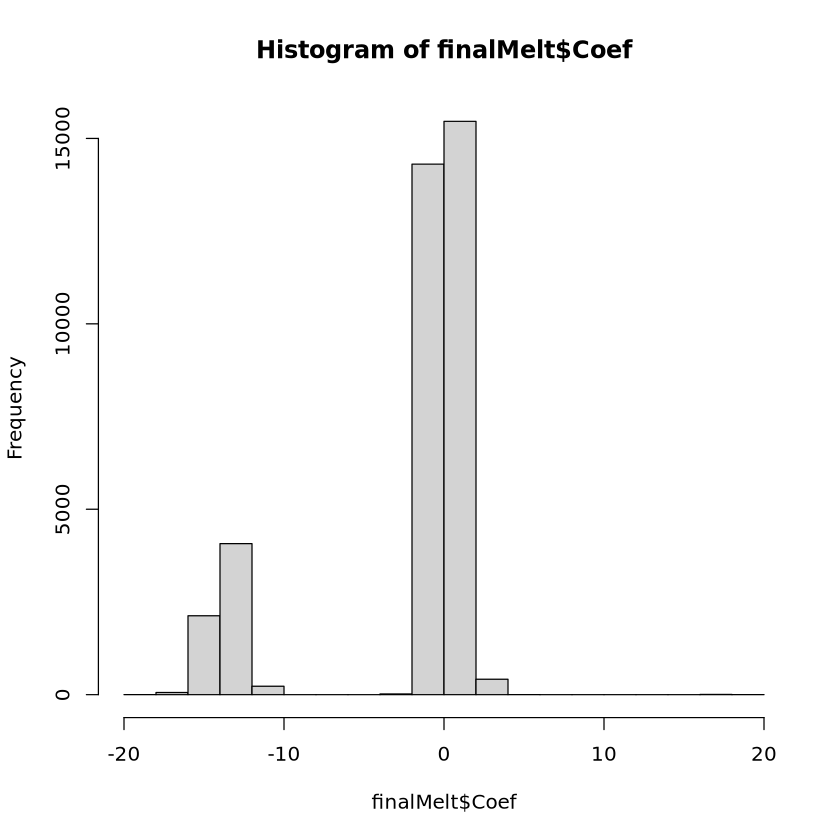

In [14]:
head(finalMelt)
hist(finalMelt$Coef)
#finalMelt[(finalMelt$BonP < 0.05) & (finalMelt$Pattern == "Up"),] %>% arrange(NomP) # & (finalMelt$TF == "MA0488.1")

In [40]:
# Volcano Plot
InspectMerge <- finalMelt %>% select(TF, Coef, NomP, BonP) %>% arrange(TF)

datAvBShrunk <- InspectMerge %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 20)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.1))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_TestVolcano_FDR01.pdf"), width=6, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.2, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = TF), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none", text=element_text(size=18)) + 
        xlab("Enrichment coefficient") + ylab("-log10(p)") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,70))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

Warning message:
“Removed 272 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [62]:
-log10(min(finalMelt$NomP))

[1] 49.87795

In [59]:
# Volcano Plot # Female
InspectMerge_F <- finalMelt %>% filter(Sex == "F", Coef > -9)
datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_1", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Close_Type1_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 3) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_1", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Open_Type1_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_2a", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Close_Type2a_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 5) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_2a", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Open_Type2a_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 3) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_2x", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 0)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Close_Type2x_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_F %>% filter(Type == "Type_2x", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 0)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Female_Open_Type2x_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

Warning message:
“Removed 55 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [60]:
# Volcano Plot # Male
InspectMerge_M <- finalMelt %>% filter(Sex == "M", Coef > -9)
datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_1", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 0)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Close_Type1_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_1", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 0)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Open_Type1_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_2a", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Close_Type2a_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 3) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_2a", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Open_Type2a_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 3) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_2x", Pattern == "Down") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Close_Type2x_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25, force = 2) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunk <- InspectMerge_M %>% filter(Type == "Type_2x", Pattern == "Up") %>% arrange(BonP)
HighSig <- head(datAvBShrunk, n = 1)
#HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig)#, HighCof)
#mandb <- c("#648FFF","#dddddd", "#DC267F")
datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$BonP < 0.05))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/TFEnrich_All3k_Male_Open_Type2x_Volcano_FDR005_More.pdf"), width=4, height=5)
    mygg <- ggplot(data=datAvBShrunk, aes(x=Coef, y=-log10(NomP)))+
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.5, aes(color = ColorCode))+
        geom_label_repel(data = unique(Repel), aes(x=Coef, y=-log10(NomP),
                           label = Plot), size = 4, min.segment.length = 0, max.overlaps = 25) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        xlim(c(-3,3)) + ylim(c(0,55))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

Warning message:
“Removed 14 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

In [63]:
print("Female or Male MAST")
InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_1")
InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_1")

CompDF <- merge(InspectMerge_FT,InspectMerge_MT, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.05,]$ColorBlock <- "FDR < 0.05 in Female"
#CompDF[CompDF$Bon_M < 0.05,]$ColorBlock <- "FDR < 0.05 in Male"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareFemalevMaleFDRP005_Type1_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-20,20) + ylim(-20,20) + 
        scale_color_manual(values=c("#FF2222")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_2a")
InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_2a")

CompDF <- merge(InspectMerge_FT,InspectMerge_MT, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.05,]$ColorBlock <- "FDR < 0.05 in Female"
CompDF[CompDF$Bon_M < 0.05,]$ColorBlock <- "FDR < 0.05 in Male"
CompDF[(CompDF$Bon_F < 0.05) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareFemalevMaleFDRP005_Type2a_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-60,60) + ylim(-60,60) + 
        scale_color_manual(values=c("#000000", "#FF2222", "#2222FF")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)


InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_2x")
InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_2x")

CompDF <- merge(InspectMerge_FT,InspectMerge_MT, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
#CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Female"
CompDF[CompDF$Bon_M < 0.05,]$ColorBlock <- "FDR < 0.05 in Male"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareFemalevMaleFDRP005_Type2x_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-40,40) + ylim(-40,40) + 
        scale_color_manual(values=c("#2222FF")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

[1] "Female or Male MAST"


[1] 0.04293845

pdf 
  2

[1] 14

[1] 5

...

[1] 0.4460432

[1] 36

[1] 0.2589928

[1] 3

[1] 0.02158273

In [43]:
print("Female Open v Close")
InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_1")
InspectMerge_FO <- InspectMerge_FT %>% filter(Pattern == "Up")
InspectMerge_FC <- InspectMerge_FT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_FO,InspectMerge_FC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Female_Type1_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-20,20) + ylim(-20,20) + 
        scale_color_manual(values=c("#4AE4CB", "#CC6677")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_2a")
InspectMerge_FO <- InspectMerge_FT %>% filter(Pattern == "Up")
InspectMerge_FC <- InspectMerge_FT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_FO,InspectMerge_FC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Female_Type2a_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-20,20) + ylim(-20,20) + 
        scale_color_manual(values=c("#4AE4CB", "#CC6677")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

InspectMerge_FT <- InspectMerge_F %>% filter(Type == "Type_2x")
InspectMerge_FO <- InspectMerge_FT %>% filter(Pattern == "Up")
InspectMerge_FC <- InspectMerge_FT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_FO,InspectMerge_FC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
#CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Female_Type2x_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-20,20) + ylim(-20,20) + 
        scale_color_manual(values=c("#4AE4CB")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

[1] "Female Open v Close"


pdf 
  2

Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


...

[1] 0

[1] 0

[1] 0

[1] 1

[1] 1

In [42]:
print("Male Open v Close")
InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_1")
InspectMerge_MO <- InspectMerge_MT %>% filter(Pattern == "Up")
InspectMerge_MC <- InspectMerge_MT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_MO,InspectMerge_MC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Male_Type1_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-20,20) + ylim(-20,20) + 
        scale_color_manual(values=c("#4AE4CB", "#CC6677")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_2a")
InspectMerge_MO <- InspectMerge_MT %>% filter(Pattern == "Up")
InspectMerge_MC <- InspectMerge_MT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_MO,InspectMerge_MC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Male_Type2a_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-60,60) + ylim(-60,60) + 
        scale_color_manual(values=c("#4AE4CB", "#CC6677")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

InspectMerge_MT <- InspectMerge_M %>% filter(Type == "Type_2x")
InspectMerge_MO <- InspectMerge_MT %>% filter(Pattern == "Up")
InspectMerge_MC <- InspectMerge_MT %>% filter(Pattern == "Down")

CompDF <- merge(InspectMerge_MO,InspectMerge_MC, by = "TF") %>% dplyr::select(TF, NomP.x, BonP.x, Coef.x, NomP.y, BonP.y, Coef.y)
colnames(CompDF) <- c("Row.names", "P_F", "Bon_F", "Coef_F", "P_M", "Bon_M", "Coef_M")
CompDF$modp.Female <- -log10(CompDF$P_F)*sign(CompDF$Coef_F)
CompDF$modp.Male <- -log10(CompDF$P_M)*sign(CompDF$Coef_M)
if (nrow(CompDF[(is.na(CompDF$Bon_F)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_F)),]$Bon_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$Bon_M)),]) > 0) {
    CompDF[(is.na(CompDF$Bon_M)),]$Bon_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$Bon_F < 0.1,]$ColorBlock <- "FDR < 0.1 in Open"
CompDF[CompDF$Bon_M < 0.1,]$ColorBlock <- "FDR < 0.1 in Close"
#CompDF[(CompDF$Bon_F < 0.1) & (CompDF$Bon_M < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/CompareOpenvCloseFDRP01_Male_Type2x_TFEnrich.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(P_F)*sign(Coef_F), y=-log10(P_M)*sign(Coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=18)) + xlim(-40,40) + ylim(-40,40) + 
        scale_color_manual(values=c("#4AE4CB", "#CC6677")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male < -2), ]
CompDF[(CompDF$modp.Female < -2) & (CompDF$modp.Male > 2), ]
CompDF[(CompDF$modp.Female > 2) & (CompDF$modp.Male < -2), ]

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

[1] "Male Open v Close"


pdf 
  2

Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


Row.names,P_F,Bon_F,Coef_F,P_M,Bon_M,Coef_M,modp.Female,modp.Male,ColorBlock
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


...

[1] 0.1282051

[1] 21

[1] 0.5384615

[1] 5

[1] 0.1282051

In [6]:
## Motif Density results read
## Adapted from Peter's python script
motifBed <- "/scratch/scjp_root/scjp0/porchard/aging-motif-density/data/motifs/NR3C1_known18.bed"
mastResFile <- "/scratch/scjp_root/scjp0/porchard/aging-motif-density/data/age-association/M.Type_2a.tsv"
outName <- "M.Type_2a.NR3C1_known18"
tssBed <- "/nfs/turbo/umms-scjp/shared_data/reference/human/hg38/topmed/tss/hg38.gene-id.tss.bed"
 
PEAK_CENTER_FLANK <- 1000
outDir <- "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots"
 
motifName <- sub("\\.bed$", "", basename(motifBed))


In [7]:
mastRes <- read.table(mastResFile, header = TRUE)
colnames(mastRes) <- c("index", "group_i", "beta", "beta_se", "beta_z", "beta_p", "beta_LRT", "beta_FDR")
coords <- tstrsplit(mastRes$index, ":", fixed = TRUE)
mastRes$chrom <- coords[[1]]
mastRes$start <- as.integer(coords[[2]])
mastRes$end <- as.integer(coords[[3]])

setorder(mastRes, beta_z)

In [12]:
mastRes$beta_z

[1] -6.244312e+00 -6.143608e+00 -6.038840e+00 -5.972308e+00 -5.928107e+00
    [6] -5.699635e+00 -5.605534e+00 -5.539784e+00 -5.527099e+00 -5.483099e+00
   [11] -5.482030e+00 -5.452234e+00 -5.416880e+00 -5.416599e+00 -5.373452e+00
   [16] -5.364831e+00 -5.356721e+00 -5.339500e+00 -5.337783e+00 -5.332264e+00
   [21] -5.329543e+00 -5.315677e+00 -5.297322e+00 -5.278386e+00 -5.272586e+00
   [26] -5.226785e+00 -5.223913e+00 -5.223384e+00 -5.211555e+00 -5.190093e+00
   [31] -5.186451e+00 -5.151638e+00 -5.148820e+00 -5.139568e+00 -5.125336e+00
   [36] -5.123489e+00 -5.122430e+00 -5.103823e+00 -5.096350e+00 -5.083749e+00
   [41] -5.063120e+00 -5.041531e+00 -5.027411e+00 -5.026083e+00 -5.021893e+00
   [46] -5.010140e+00 -5.004938e+00 -4.985941e+00 -4.973409e+00 -4.971305e+00
   [51] -4.960413e+00 -4.953808e+00 -4.926124e+00 -4.924776e+00 -4.922774e+00
   [56] -4.912100e+00 -4.896331e+00 -4.888679e+00 -4.866846e+00 -4.865897e+00
   [61] -4.865763e+00 -4.860759e+00 -4.859638e+00 -4.850813e+00 -4.846376e+00
   [66] -4.842164e+00 -4.815527e+00 -4.805838e+00 -4.801447e+00 -4.800879e+00
   [71] -4.795014e+00 -4.791705e+00 -4.776832e+00 -4.776681e+00 -4.761740e+00
   [76] -4.760064e+00 -4.744958e+00 -4.740998e+00 -4.736115e+00 -4.734337e+00
   [81] -4.733754e+00 -4.732136e+00 -4.715086e+00 -4.713579e+00 -4.710245e+00
   [86] -4.697352e+00 -4.696425e+00 -4.696367e+00 -4.693514e+00 -4.691438e+00
   [91] -4.687352e+00 -4.681670e+00 -4.678889e+00 -4.677712e+00 -4.668664e+00
   [96] -4.665394e+00 -4.654277e+00 -4.650225e+00 -4.648764e+00 -4.639598e+00
  [101] -4.630613e+00 -4.628447e+00 -4.618893e+00 -4.612793e+00 -4.608835e+00
  [106] -4.604163e+00 -4.601300e+00 -4.597394e+00 -4.591111e+00 -4.590364e+00
  [111] -4.573523e+00 -4.570291e+00 -4.563761e+00 -4.563399e+00 -4.561494e+00
  [116] -4.554491e+00 -4.549979e+00 -4.542244e+00 -4.541794e+00 -4.536203e+00
  [121] -4.533033e+00 -4.524752e+00 -4.523368e+00 -4.521704e+00 -4.520704e+00
  [126] -4.517511e+00 -4.512338e+00 -4.505010e+00 -4.500493e+00 -4.491867e+00
  [131] -4.491093e+00 -4.481811e+00 -4.471589e+00 -4.465207e+00 -4.462786e+00
  [136] -4.458213e+00 -4.443998e+00 -4.442583e+00 -4.440273e+00 -4.428786e+00
  [141] -4.427682e+00 -4.419402e+00 -4.418644e+00 -4.414792e+00 -4.398151e+00
  [146] -4.389910e+00 -4.389098e+00 -4.384800e+00 -4.383252e+00 -4.381822e+00
  [151] -4.374886e+00 -4.374392e+00 -4.364096e+00 -4.363624e+00 -4.357467e+00
  [156] -4.355977e+00 -4.355198e+00 -4.351189e+00 -4.335866e+00 -4.329879e+00
  [161] -4.329378e+00 -4.327971e+00 -4.323006e+00 -4.318559e+00 -4.317573e+00
  [166] -4.311347e+00 -4.307472e+00 -4.304271e+00 -4.301719e+00 -4.300624e+00
  [171] -4.300090e+00 -4.298941e+00 -4.292548e+00 -4.290970e+00 -4.288668e+00
  [176] -4.279664e+00 -4.277980e+00 -4.274978e+00 -4.269410e+00 -4.265988e+00
  [181] -4.263901e+00 -4.256870e+00 -4.254815e+00 -4.254631e+00 -4.254116e+00
  [186] -4.253260e+00 -4.251534e+00 -4.247035e+00 -4.245643e+00 -4.224974e+00
  [191] -4.224452e+00 -4.213959e+00 -4.203127e+00 -4.198184e+00 -4.193139e+00
  [196] -4.190264e+00 -4.188987e+00 -4.187681e+00 -4.182207e+00 -4.181870e+00
  [201] -4.181418e+00 -4.178797e+00 -4.177857e+00 -4.172852e+00 -4.171215e+00
  [206] -4.170198e+00 -4.168253e+00 -4.168139e+00 -4.165742e+00 -4.165178e+00
  [211] -4.163678e+00 -4.163422e+00 -4.159308e+00 -4.153365e+00 -4.153214e+00
  [216] -4.148989e+00 -4.146779e+00 -4.138134e+00 -4.137602e+00 -4.134485e+00
  [221] -4.132418e+00 -4.130309e+00 -4.126111e+00 -4.125883e+00 -4.125051e+00
  [226] -4.123709e+00 -4.119469e+00 -4.116963e+00 -4.115327e+00 -4.114660e+00
  [231] -4.114505e+00 -4.108865e+00 -4.106206e+00 -4.103985e+00 -4.101891e+00
  [236] -4.096591e+00 -4.095921e+00 -4.093044e+00 -4.088892e+00 -4.086323e+00
  [241] -4.085751e+00 -4.084208e+00 -4.083962e+00 -4.074497e+00 -4.066816e+00
  [246] -4.062950e+00 -4.060953e+00 -4.058279e+00 -4.055270e+00 -4.051085e+00
  [251] -4.050441e+00 -4.047612e+00 -4.045177e+00 -4.039809e+00 -4.039611e+00
  [256] -4.035371e+00 -4.0

In [8]:

mastRes$rDex <- seq(1,nrow(mastRes))

mastRes$center <- as.integer(round((mastRes$start + mastRes$end) / 2))
mastRes$winStart <- mastRes$center - PEAK_CENTER_FLANK
mastRes$winEnd <- mastRes$center + PEAK_CENTER_FLANK
head(mastRes)

,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
chr18:50582541:50582842,chr18:50582541:50582842,age,-0.03011127,0.004822191,-6.244312,4.256683e-10,2.473918e-09,0.0001040950,chr18,50582541,50582842,1,50582692,50581692,50583692
chr6:113676993:113677294,chr6:113676993:113677294,age,-0.02335115,0.003800885,-6.143608,8.066791e-10,9.208443e-09,0.0001291546,chr6,113676993,113677294,2,113677144,113676144,113678144
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.02050416,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128
chr3:177516094:177516395,chr3:177516094:177516395,age,-0.02079156,0.003481327,-5.972308,2.339199e-09,2.761872e-08,0.0002324226,chr3,177516094,177516395,4,177516244,177515244,177517244
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.01536713,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552
chr22:44658384:44658685,chr22:44658384:44658685,age,-0.04028123,0.007067335,-5.699635,1.200639e-08,5.091732e-08,0.0003570747,chr22,44658384,44658685,6,44658534,44657534,44659534


In [7]:
tail(mastRes)

,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
chr10:7260507:7260808,chr10:7260507:7260808,age,0.011494036,0.0023096125,4.976608,6.470817e-07,1.865899e-06,0.0013536452,chr10,7260507,7260808,42066,7260658,7259658,7261658
chr1:59689812:59690113,chr1:59689812:59690113,age,0.014480490,0.0028728796,5.040410,4.645362e-07,1.426261e-06,0.0011767215,chr1,59689812,59690113,42067,59689962,59688962,59690962
chr2:65436464:65436765,chr2:65436464:65436765,age,0.006331177,0.0012444103,5.087693,3.624458e-07,1.039705e-06,0.0010173876,chr2,65436464,65436765,42068,65436614,65435614,65437614
chr22:41448311:41448612,chr22:41448311:41448612,age,0.005097756,0.0009583101,5.319526,1.040378e-07,2.325438e-07,0.0005469801,chr22,41448311,41448612,42069,41448462,41447462,41449462
chr8:131916571:131916872,chr8:131916571:131916872,age,0.012586425,0.0022957197,5.482562,4.192109e-08,1.802216e-07,0.0005469801,chr8,131916571,131916872,42070,131916722,131915722,131917722
chr4:168119937:168120238,chr4:168119937:168120238,age,0.016319811,0.0028237872,5.779405,7.496512e-09,7.320099e-08,0.0003850098,chr4,168119937,168120238,42071,168120088,168119088,168121088


In [12]:
queryHits(dtn)

[1]     1     2     3     4     5     6     7     8     9    10    11    12
   [13]    13    14    15    16    17    18    19    20    21    22    23    24
   [25]    25    26    27    28    29    30    31    32    33    34    35    36
   [37]    37    38    39    40    41    42    43    44    45    46    47    48
   [49]    49    50    51    52    53    54    55    56    57    58    59    60
   [61]    61    62    63    64    65    66    67    68    69    70    71    72
   [73]    73    74    75    76    77    78    79    80    81    82    83    84
   [85]    85    86    87    88    89    90    91    92    93    94    95    96
   [97]    97    98    99   100   101   102   103   104   105   106   107   108
  [109]   109   110   111   112   113   114   115   116   117   118   119   120
  [121]   121   122   123   124   125   126   127   128   129   130   131   132
  [133]   133   134   135   136   137   138   139   140   141   142   143   144
  [145]   145   146   147   148   149   150   151   152   153   154   155   156
  [157]   157   158   159   160   161   162   163   164   165   166   167   168
  [169]   169   170   171   172   173   174   175   176   177   178   179   180
  [181]   181   182   183   184   185   186   187   188   189   190   191   192
  [193]   193   194   195   196   197   198   199   200   201   202   203   204
  [205]   205   206   207   208   209   210   211   212   213   214   215   216
  [217]   217   218   219   220   221   222   223   224   225   226   227   228
  [229]   229   230   231   232   233   234   235   236   237   238   239   240
  [241]   241   242   243   244   245   246   247   248   249   250   251   252
  [253]   253   254   255   256   257   258   259   260   261   262   263   264
  [265]   265   266   267   268   269   270   271   272   273   274   275   276
  [277]   277   278   279   280   281   282   283   284   285   286   287   288
  [289]   289   290   291   292   293   294   295   296   297   298   299   300
  [301]   301   302   303   304   305   306   307   308   309   310   311   312
  [313]   313   314   315   316   317   318   319   320   321   322   323   324
  [325]   325   326   327   328   329   330   331   332   333   334   335   336
  [337]   337   338   339   340   341   342   343   344   345   346   347   348
  [349]   349   350   351   352   353   354   355   356   357   358   359   360
  [361]   361   362   363   364   365   366   367   368   369   370   371   372
  [373]   373   374   375   376   377   378   379   380   381   382   383   384
  [385]   385   386   387   388   389   390   391   392   393   394   395   396
  [397]   397   398   399   400   401   402   403   404   405   406   407   408
  [409]   409   410   411   412   413   414   415   416   417   418   419   420
  [421]   421   422   423   424   425   426   427   428   429   430   431   432
  [433]   433   434   435   436   437   438   439   440   441   442   443   444
  [445]   445   446   447   448   449   450   451   452   453   454   455   456
  [457]   457   458   459   460   461   462   463   464   465   466   467   468
  [469]   469   470   471   472   473   474   475   476   477   478   479   480
  [481]   481   482   483   484   485   486   487   488   489   490   491   492
  [493]   493   494   495   496   497   498   499   500   501   502   503   504
  [505]   505   506   507   508   509   510   511   512   513   514   515   516
  [517]   517   518   519   520   521   522   523   524   525   526   527   528
  [529]   529   530   531   532   533   534   535   536   537   538   539   540
  [541]   541   542   543   544   545   546   547   548   549   550   551   552
  [553]   553   554   555   556   557   558   559   560   561   562   563   564
  [565]   565   566   567   568   569   570   571   572   573   574   575   576
  [577]   577   578   579   580   581   582   583   584   585   586   587   588
  [589]   589   590   591   592   593   594   595   596   597   598   599   600
  [6

In [9]:
# ---- Read motif BED ----
motifFrame <- fread(motifBed, header = FALSE, select = 1:3,
                col.names = c("chrom", "start", "end"))
motifLength <- unique(motifFrame$end - motifFrame$start)[1]
motifLength
head(motifFrame)
 
# ---- TSS distal vs proximal ----
peakRanges <- GRanges(seqnames = mastRes$chrom,
                    ranges   = IRanges(start = mastRes$start,
                                       end   = mastRes$end))
tss <- fread(tssBed, header = FALSE, select = 1:3,
             col.names = c("chrom", "start", "end"))
tssRanges <- GRanges(seqnames = tss$chrom,
                  ranges   = IRanges(start = tss$start, end = tss$end))
 
dtn <- distanceToNearest(peakRanges, tssRanges)
mastRes$Distance <- -1
mastRes$Distance[queryHits(dtn)] <- mcols(dtn)$distance
head(mastRes)
mastRes$Distal5kb <- -1
mastRes[mastRes$Distance <= 5000,]$Distal5kb <- 0
mastRes[mastRes$Distance > 5000,]$Distal5kb <- 1
head(mastRes)


[1] 17

chrom,start,end
<chr>,<int>,<int>
chr1,17443,17460
chr1,17443,17460
chr1,19009,19026
chr1,19009,19026
chr1,32238,32255
chr1,32238,32255


,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd,Distance
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
chr18:50582541:50582842,chr18:50582541:50582842,age,-0.03011127,0.004822191,-6.244312,4.256683e-10,2.473918e-09,0.0001040950,chr18,50582541,50582842,1,50582692,50581692,50583692,21898
chr6:113676993:113677294,chr6:113676993:113677294,age,-0.02335115,0.003800885,-6.143608,8.066791e-10,9.208443e-09,0.0001291546,chr6,113676993,113677294,2,113677144,113676144,113678144,26902
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.02050416,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128,207
chr3:177516094:177516395,chr3:177516094:177516395,age,-0.02079156,0.003481327,-5.972308,2.339199e-09,2.761872e-08,0.0002324226,chr3,177516094,177516395,4,177516244,177515244,177517244,12541
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.01536713,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552,453
chr22:44658384:44658685,chr22:44658384:44658685,age,-0.04028123,0.007067335,-5.699635,1.200639e-08,5.091732e-08,0.0003570747,chr22,44658384,44658685,6,44658534,44657534,44659534,6548


,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd,Distance,Distal5kb
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
chr18:50582541:50582842,chr18:50582541:50582842,age,-0.03011127,0.004822191,-6.244312,4.256683e-10,2.473918e-09,0.0001040950,chr18,50582541,50582842,1,50582692,50581692,50583692,21898,1
chr6:113676993:113677294,chr6:113676993:113677294,age,-0.02335115,0.003800885,-6.143608,8.066791e-10,9.208443e-09,0.0001291546,chr6,113676993,113677294,2,113677144,113676144,113678144,26902,1
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.02050416,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128,207,0
chr3:177516094:177516395,chr3:177516094:177516395,age,-0.02079156,0.003481327,-5.972308,2.339199e-09,2.761872e-08,0.0002324226,chr3,177516094,177516395,4,177516244,177515244,177517244,12541,1
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.01536713,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552,453,0
chr22:44658384:44658685,chr22:44658384:44658685,age,-0.04028123,0.007067335,-5.699635,1.200639e-08,5.091732e-08,0.0003570747,chr22,44658384,44658685,6,44658534,44657534,44659534,6548,1


In [10]:
# ---- Build motif-overlap matrix (peaks x bp) ----
nPeaks <- nrow(mastRes)
nNucs  <- 2 * PEAK_CENTER_FLANK
motifSpace <- matrix(0, nrow = nPeaks, ncol = nNucs)

# Overlaps!
windowRanges <- GRanges(seqnames = mastRes$chrom,
                      ranges   = IRanges(start = mastRes$winStart,
                                         end   = mastRes$winEnd))

motifRanges <- GRanges(seqnames = motifFrame$chrom,
                      ranges   = IRanges(start = motifFrame$start,
                                         end   = motifFrame$end))

overlapRanges <- findOverlaps(motifRanges, windowRanges)

In [11]:
motifStarts <- start(motifRanges)[queryHits(overlapRanges)]
windowStarts <- start(windowRanges)[subjectHits(overlapRanges)]

relativeStart  <- pmax(motifStarts - windowStarts, 0)
relativeEnd    <- pmin(relativeStart + motifLength, nNucs)
peakIds <- subjectHits(overlapRanges) 

In [12]:
fillPairs <- do.call(rbind, lapply(seq_along(peakIds), function(i) {
  cbind(peakIds[i], (relativeStart[i]):relativeEnd[i])
}))
motifSpace[fillPairs] <- 1


In [13]:
# ---- Bin the matrix and write the correlation file ----
peaksPerBin <- round(nPeaks / 300)
globalBin <- (seq_len(nPeaks)) %/% peaksPerBin
 
binMat <- rowsum(motifSpace, group = globalBin, reorder = TRUE)
centerCol <- binMat[, PEAK_CENTER_FLANK]
correlation <- cor(seq_len(nrow(binMat)), centerCol, method = "spearman")
 
dir.create(outDir, showWarnings = FALSE, recursive = TRUE)
write.table(data.frame(motifName, correlation),
            file = file.path(outDir, paste0(outName, ".correlationR.txt")),
            sep = "\t", row.names = FALSE, col.names = FALSE, quote = FALSE)


In [19]:
head(mastRes)

,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd,Distance,Distal5kb
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
chr18:50582541:50582842,chr18:50582541:50582842,age,-0.03011127,0.004822191,-6.244312,4.256683e-10,2.473918e-09,0.0001040950,chr18,50582541,50582842,1,50582692,50581692,50583692,21898,1
chr6:113676993:113677294,chr6:113676993:113677294,age,-0.02335115,0.003800885,-6.143608,8.066791e-10,9.208443e-09,0.0001291546,chr6,113676993,113677294,2,113677144,113676144,113678144,26902,1
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.02050416,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128,207,0
chr3:177516094:177516395,chr3:177516094:177516395,age,-0.02079156,0.003481327,-5.972308,2.339199e-09,2.761872e-08,0.0002324226,chr3,177516094,177516395,4,177516244,177515244,177517244,12541,1
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.01536713,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552,453,0
chr22:44658384:44658685,chr22:44658384:44658685,age,-0.04028123,0.007067335,-5.699635,1.200639e-08,5.091732e-08,0.0003570747,chr22,44658384,44658685,6,44658534,44657534,44659534,6548,1


In [14]:
# Format Data for Heatmap (proximal and distal peaks binned independently, no boundary needed)
setorder(mastRes, Distal5kb, beta_z)
head(mastRes)
nDex <- mastRes$rDex

motifSortSpace <- motifSpace[nDex, , drop = FALSE]
betaGrad <- mastRes$beta_z
pGrad <- mastRes$beta_FDR
ppGrad <- mastRes$beta_p

PEAKS_PER_BIN <- 150  # flexible: fixed peak count per bin, applied independently to each group

binPeakGroup <- function(distalFlag) {
  rows <- which(mastRes$Distal5kb == distalFlag)
  nPeaksGroup <- length(rows)
  peaksPerBinGroup <- PEAKS_PER_BIN
  binGroup <- seq_len(nPeaksGroup) %/% peaksPerBinGroup

  groupSpace <- motifSortSpace[rows, , drop = FALSE]
  groupBeta  <- betaGrad[rows]
  groupP     <- pGrad[rows]
  groupPp    <- ppGrad[rows]

  binMatGroup <- rowsum(groupSpace, group = binGroup, reorder = TRUE)

  binZetaGroup <- tapply(groupBeta, binGroup, median)
  binZetaGroup <- as.numeric(binZetaGroup[order(as.integer(names(binZetaGroup)))])

  binPGroup <- tapply(groupP, binGroup, median)
  binPGroup <- as.numeric(binPGroup[order(as.integer(names(binPGroup)))])

  binPGradGroup <- tapply(groupPp, binGroup, median)
  binPGradGroup <- as.numeric(binPGradGroup[order(as.integer(names(binPGradGroup)))])

  binPpGroup <- tapply(groupPp, binGroup, median)
  binPpGroup <- as.numeric(binPpGroup[order(as.integer(names(binPpGroup)))])

  list(binMat = binMatGroup,
       binZeta = binZetaGroup,
       binP = binPGroup,
       binPGrad = binPGradGroup,
       binPp = binPpGroup,
       globalBin = sort(unique(binGroup)),
       peaksPerBin = peaksPerBinGroup)
}

proximalBins <- binPeakGroup(0)
distalBins   <- binPeakGroup(1)

head(proximalBins$binZeta)
head(distalBins$binZeta)

,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd,Distance,Distal5kb
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.02050416,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128,207,0
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.01536713,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552,453,0
chr11:12537818:12538119,chr11:12537818:12538119,age,-0.01951790,0.003559648,-5.483099,4.179395e-08,1.612169e-07,0.0005469801,chr11,12537818,12538119,10,12537968,12536968,12538968,2846,0
chr1:165423257:165423558,chr1:165423257:165423558,age,-0.02248555,0.004124099,-5.452234,4.974090e-08,2.277800e-07,0.0005469801,chr1,165423257,165423558,12,165423408,165422408,165424408,1412,0
chr16:54286809:54287110,chr16:54286809:54287110,age,-0.02184466,0.004032910,-5.416599,6.074335e-08,2.131797e-07,0.0005469801,chr16,54286809,54287110,14,54286960,54285960,54287960,21,0
chr18:45619493:45619794,chr18:45619493:45619794,age,-0.02173946,0.004161949,-5.223384,1.756827e-07,6.261471e-07,0.0008252493,chr18,45619493,45619794,28,45619644,45618644,45620644,4011,0


[1] -4.132418 -3.536848 -3.245555 -3.030101 -2.850558 -2.710385

[1] -4.563761 -3.893746 -3.502752 -3.264276 -3.042848 -2.878246

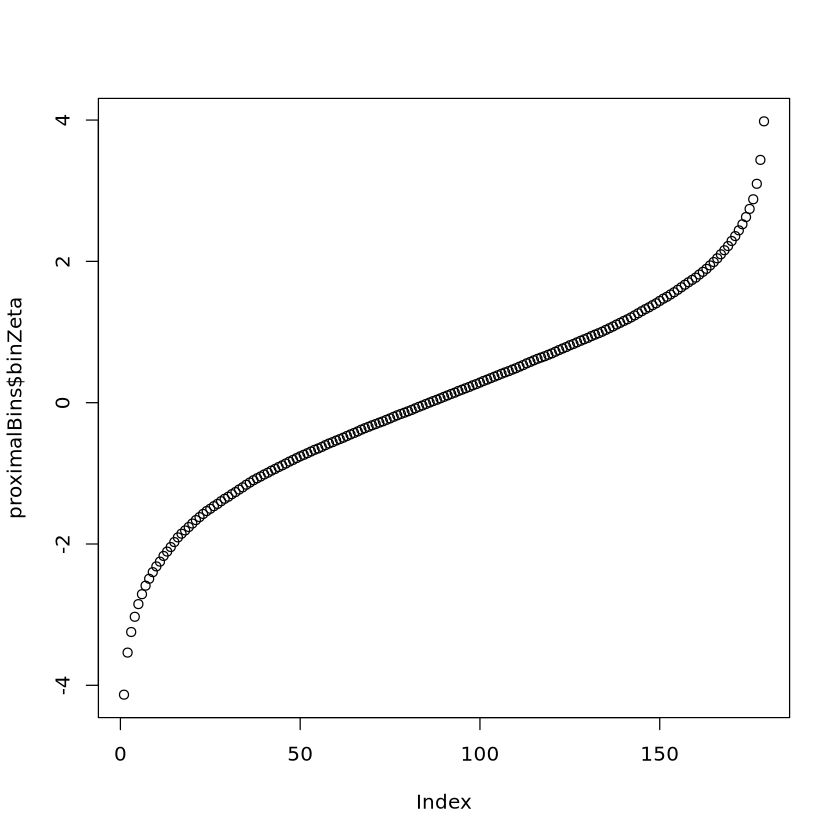

0,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
1,2,2,2,2,2,2,2,2,2,2,⋯,1,0,0,0,0,0,0,0,0,0
2,1,1,1,1,1,1,1,1,1,1,⋯,0,0,0,0,0,0,0,0,0,0
3,1,1,1,1,1,1,1,1,1,1,⋯,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,⋯,1,1,1,1,1,2,2,2,1,1
5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,1,1,1,1


0,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,⋯,0,1,1,1,1,1,1,1,1,1
2,1,1,1,1,1,1,1,1,1,1,⋯,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,⋯,1,0,0,0,0,0,0,0,0,0
4,1,1,1,1,1,2,2,2,2,2,⋯,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,⋯,1,1,1,1,1,1,1,1,1,1


[1] 0

[1] 0

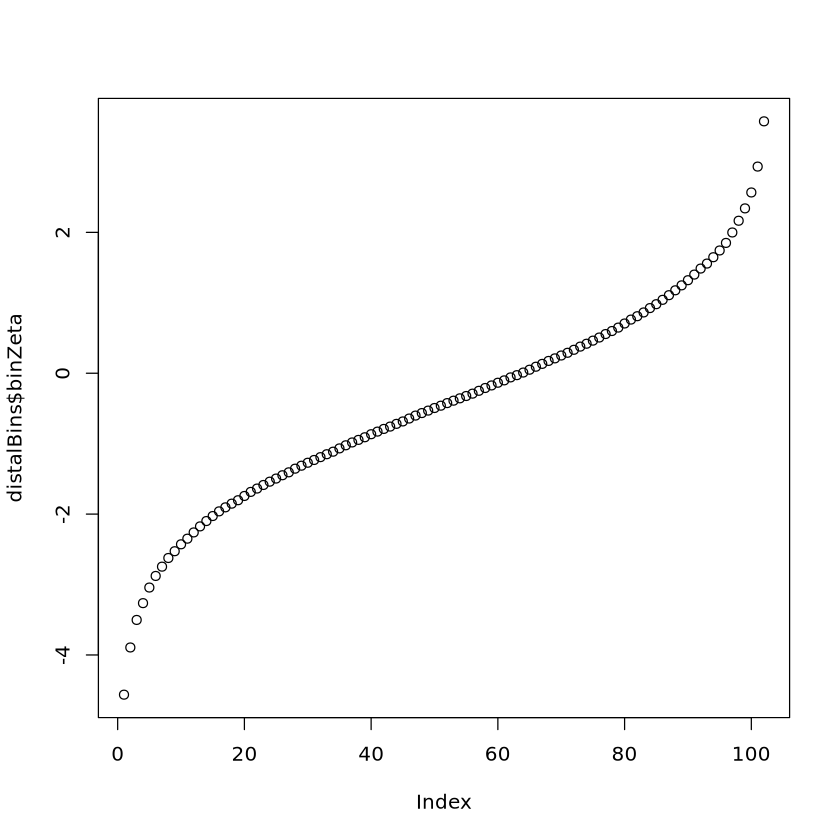

In [15]:
plot(proximalBins$binZeta)
plot(distalBins$binZeta)
head(proximalBins$binMat)
head(distalBins$binMat)
min(proximalBins$globalBin)
min(distalBins$globalBin)

In [47]:
# ---- Heatmap (proximal and distal peaks, plotted separately) ----
makeHeatmap <- function(bins) {
  binMatDT <- as.data.table(bins$binMat)
  binMatDT$bin <- bins$globalBin
  binMatHeat <- melt(binMatDT, id.vars = "bin",
                    variable.name = "position", value.name = "count")
  binMatHeat$position <- as.integer(sub("V", "", binMatHeat$position))

  ggplot(binMatHeat, aes(x = bin, y = position, fill = count)) +
    geom_raster() +
    scale_fill_viridis_c(option = "B", limits = c(0,4), values = scales::rescale(c(0, 1, 1.5, 2, 3, 4))) +
    scale_y_continuous(
      breaks = c(0, PEAK_CENTER_FLANK, 2 * PEAK_CENTER_FLANK),
      labels = c("", "", ""),
      expand = c(0, 0)) +
    scale_x_discrete(
      breaks = c(min(bins$globalBin), max(bins$globalBin)),
      labels = c("", ""),
      expand = c(0, 0)) +
    theme_minimal(base_size = 24) +
    theme(panel.grid = element_blank(),
          legend.position  = "none") +
    labs(y = "",
         x = paste0(length(bins$globalBin), " bins (", bins$peaksPerBin, " peaks per bin)"))
}

myHeatmapProximal <- makeHeatmap(proximalBins)
myHeatmapDistal   <- makeHeatmap(distalBins)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlapZeros_proximal.pdf"), width=11, height=4)
print(myHeatmapProximal)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlapZeros_distal.pdf"), width=6, height=4)
print(myHeatmapDistal)
dev.off()

pdf 
  2

In [53]:
# ---- Heatmap (single panel) ----
binMat <- as.data.table(binMat)
binMat$bin <- globalBin
binMatHeat <- melt(binMat, id.vars = "bin",
                  variable.name = "position", value.name = "count")
binMatHeat$position <- as.integer(sub("V", "", binMatHeat$position))
 
myHeatmap <- ggplot(binMatHeat, aes(x = bin, y = position, fill = count)) +
  geom_raster() +
  scale_fill_viridis_c(option = "B", limits = c(0,3), values = scales::rescale(c(0, 0.5, 1, 2, 3))) +
  scale_y_continuous(
    breaks = c(0, PEAK_CENTER_FLANK, 2 * PEAK_CENTER_FLANK),
    labels = c("", 0, ""),
    expand = c(0, 0)) +
  scale_x_discrete(
    breaks = c(min(globalBin), boundary_y, max(globalBin)),
    labels = c("", "", ""),
    expand = c(0, 0)) +
  geom_vline(xintercept = boundary_y, color = "white", linewidth = 0.5) +
  theme_minimal(base_size = 24) +
  theme(panel.grid = element_blank()) +
  labs(y = "",
       x = paste0(length(globalBin), " bins (", peaksPerBin, " peaks per bin)"))

#ggplot2::ggsave(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlapTest.pdf"), myHeatmap, width = 16, height = 4)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlapZeros.pdf"), width=16, height=4)
#png(filename = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlap.png"),    width    = 8, height = 4, units = "in", res      = 150, bg       = "white")

print(myHeatmap)
dev.off()

binMat <- as.data.table(binMat)
binMat$bin <- globalBin
binMatHeat <- melt(binMat, id.vars = "bin",
                  variable.name = "position", value.name = "count")
binMatHeat$position <- as.integer(sub("V", "", binMatHeat$position))
 
myHeatmapLedge <- ggplot(binMatHeat, aes(x = bin, y = position, fill = count)) +
  geom_raster() +
  scale_fill_viridis_c(option = "B", limits = c(0,3), values = scales::rescale(c(0, 0.5, 1, 2, 3))) +
  scale_y_continuous(
    breaks = c(0, PEAK_CENTER_FLANK, 2 * PEAK_CENTER_FLANK),
    labels = c("", "", ""),
    expand = c(0, 0)) +
  scale_x_discrete(
    breaks = c(min(globalBin), boundary_y, max(globalBin)),
    labels = c("", "", ""),
    expand = c(0, 0)) +
  geom_vline(xintercept = boundary_y, color = "white", linewidth = 0.5) +
  theme_minimal(base_size = 24) +
  theme(panel.grid = element_blank()) +
  labs(y = "",
       x ="")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_motifOverlapZeros_Ledge.pdf"), width=2, height=4)
print(myHeatmapLedge)
dev.off()

pdf 
  2

pdf 
  2

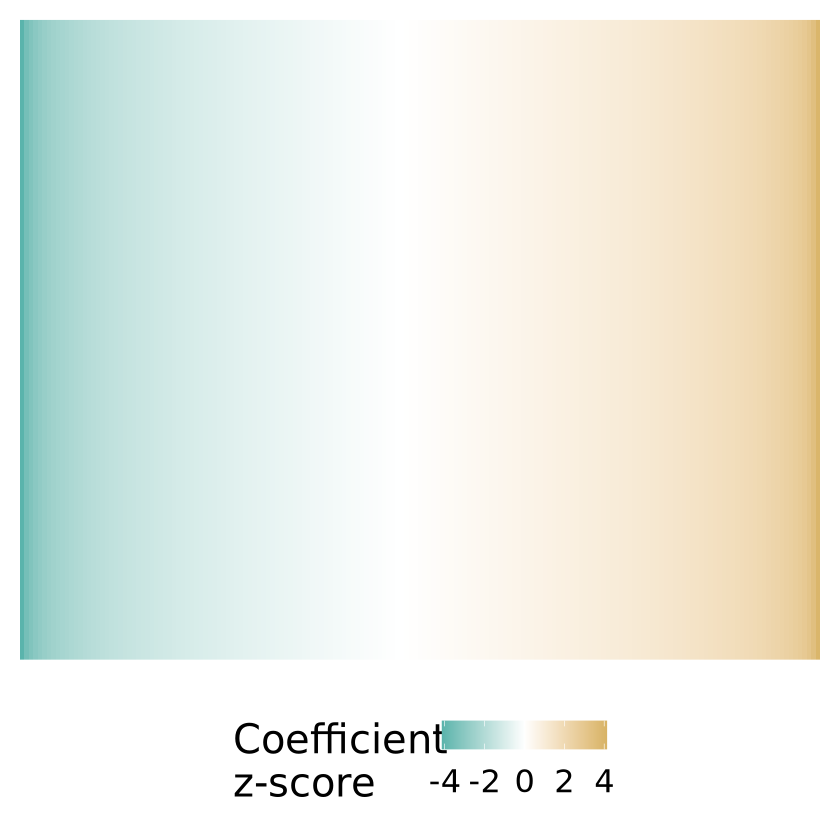

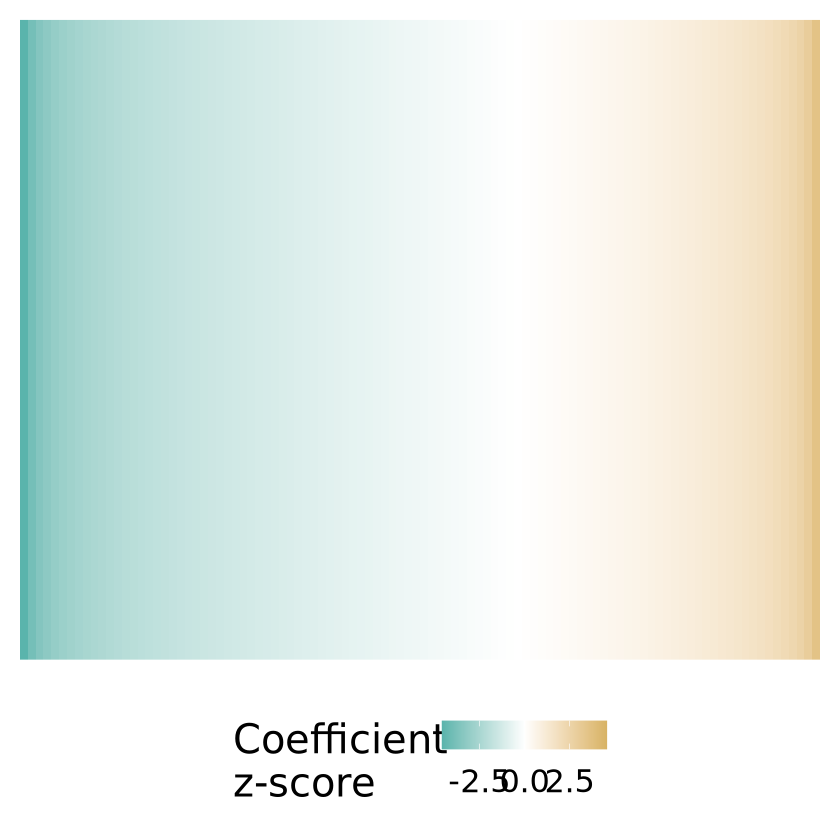

In [ ]:
# ---- beta z-score panel (proximal and distal peaks, plotted separately) ----
makeGradientPanel <- function(bins, values, low, mid, high, limits, legendName) {
  betaFrame <- data.frame(bin = bins$globalBin, fc = values)
  ggplot(betaFrame, aes(x = bin, y = 1, fill = fc)) +
    geom_raster() +
    scale_fill_gradient2(low = low, mid = mid, high = high,
                         midpoint = 0, limits = limits,
                         name = legendName) +
    scale_y_continuous(breaks = NULL, expand = c(0, 0)) +
    scale_x_discrete(breaks = NULL, expand = c(0, 0)) +
    theme_minimal(base_size = 24) +
    theme(panel.grid       = element_blank(),
          axis.title       = element_blank(),
          axis.text        = element_blank(),
          legend.position  = "none",
          legend.key.width = unit(0.3, "cm"))
}

betaMaxProximal <- max(abs(proximalBins$binZeta))
betaMaxDistal   <- max(abs(distalBins$binZeta))

myZscoreProximal <- makeGradientPanel(proximalBins, proximalBins$binZeta,
                                       "#5ab4ac", "white", "#d8b365",
                                       c(-betaMaxProximal, betaMaxProximal), "Coefficient\nz-score")
myZscoreDistal   <- makeGradientPanel(distalBins, distalBins$binZeta,
                                       "#5ab4ac", "white", "#d8b365",
                                       c(-betaMaxDistal, betaMaxDistal), "Coefficient\nz-score")

myZscoreProximal
myZscoreDistal
    
#pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_zGrad_proximal.pdf"), width=11, height=3)
print(myZscoreProximal)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_zGrad_distal.pdf"), width=6, height=3)
print(myZscoreDistal)
dev.off()

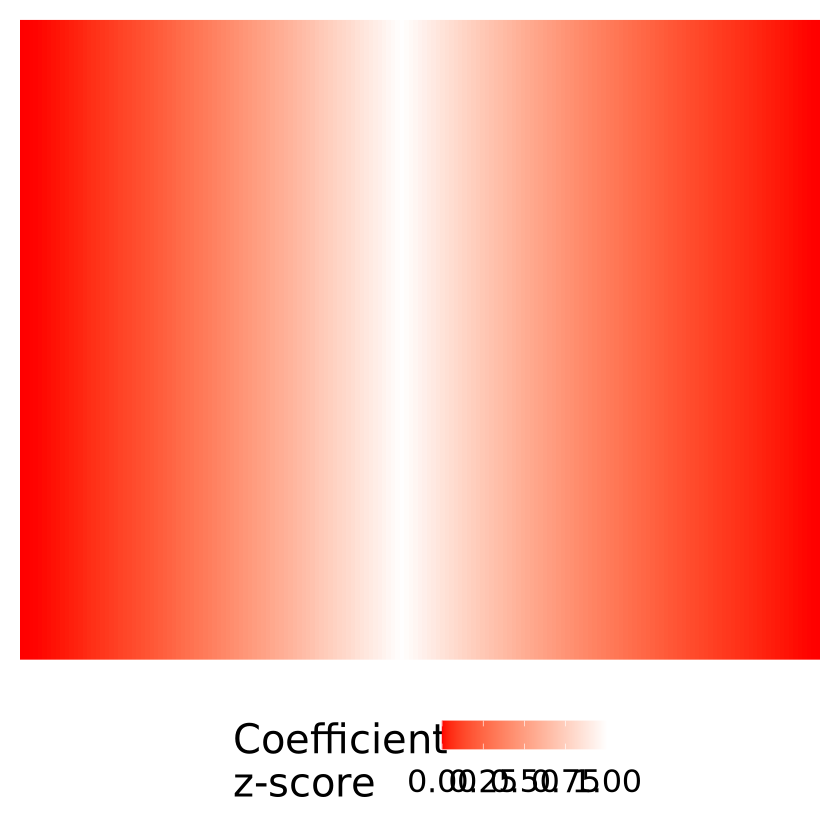

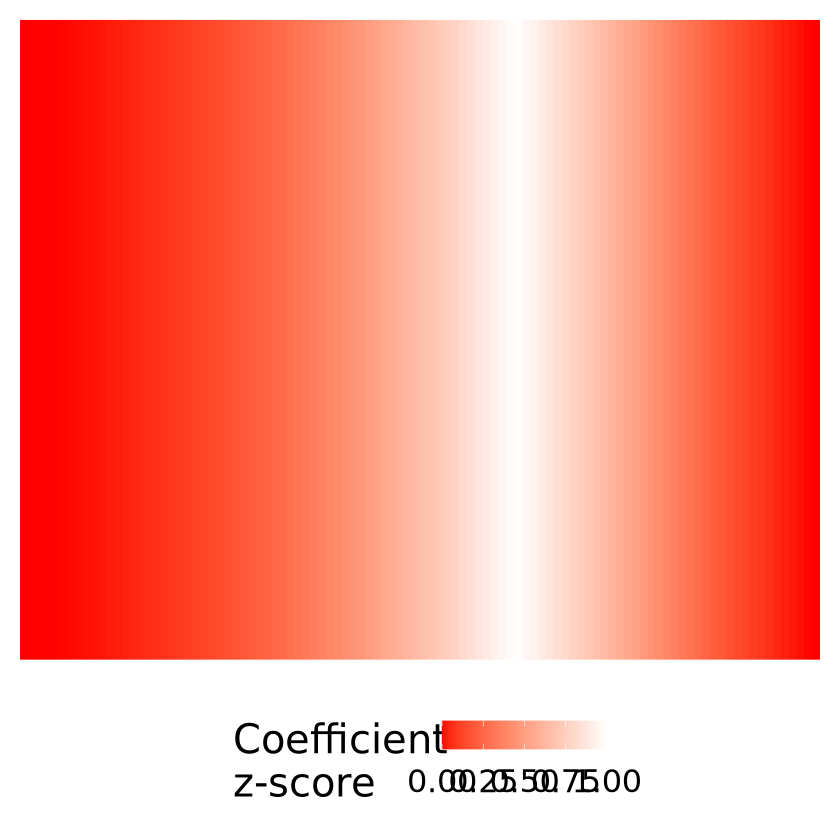

In [ ]:
# ---- p grad panel (proximal and distal peaks, plotted separately) ----
myPGradProximal <- makeGradientPanel(proximalBins, proximalBins$binPGrad,
                                      "#3B4CC0", "#FF0000", "#FFFFFF", c(0, 1), "Coefficient\nz-score")
myPGradDistal   <- makeGradientPanel(distalBins, distalBins$binPGrad,
                                      "#3B4CC0", "#FF0000", "#FFFFFF", c(0, 1), "Coefficient\nz-score")

myPGradProximal
myPGradDistal

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_ppGrad_proximal.pdf"), width=11, height=3)
print(myPGradProximal)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_ppGrad_distal.pdf"), width=6, height=3)
print(myPGradDistal)
dev.off()

In [40]:
(distalBins$binPGrad)

[1] 5.024534e-06 9.870799e-05 4.604798e-04 1.097443e-03 2.343521e-03
  [6] 3.998940e-03 6.026692e-03 8.706750e-03 1.149516e-02 1.513915e-02
 [11] 1.882005e-02 2.379804e-02 2.964493e-02 3.583708e-02 4.259151e-02
 [16] 4.982530e-02 5.686333e-02 6.406349e-02 7.135110e-02 8.137317e-02
 [21] 9.197885e-02 1.015414e-01 1.125626e-01 1.236589e-01 1.347636e-01
 [26] 1.474449e-01 1.593668e-01 1.753472e-01 1.892155e-01 2.037162e-01
 [31] 2.180111e-01 2.334783e-01 2.500991e-01 2.652807e-01 2.857262e-01
 [36] 3.061411e-01 3.256486e-01 3.438444e-01 3.631571e-01 3.864022e-01
 [41] 4.072238e-01 4.289708e-01 4.487157e-01 4.722122e-01 4.935705e-01
 [46] 5.199418e-01 5.476014e-01 5.715674e-01 5.956709e-01 6.213426e-01
 [51] 6.448888e-01 6.713918e-01 6.967346e-01 7.213150e-01 7.462237e-01
 [56] 7.718705e-01 8.028213e-01 8.338009e-01 8.622394e-01 8.924468e-01
 [61] 9.190867e-01 9.525748e-01 9.780010e-01 9.923576e-01 9.602584e-01
 [66] 9.265125e-01 8.944779e-01 8.615378e-01 8.331085e-01 8.013595e-01
 [71] 7.716803e-01 7.394200e-01 7.055326e-01 6.754242e-01 6.436224e-01
 [76] 6.123666e-01 5.781472e-01 5.491597e-01 5.170916e-01 4.802897e-01
 [81] 4.463294e-01 4.183877e-01 3.882896e-01 3.551371e-01 3.270625e-01
 [86] 2.974197e-01 2.678730e-01 2.391120e-01 2.122519e-01 1.866647e-01
 [91] 1.613839e-01 1.373062e-01 1.195242e-01 9.959287e-02 8.140163e-02
 [96] 6.432503e-02 4.570565e-02 3.040397e-02 1.927457e-02 1.028218e-02
[101] 3.348821e-03 3.488484e-04

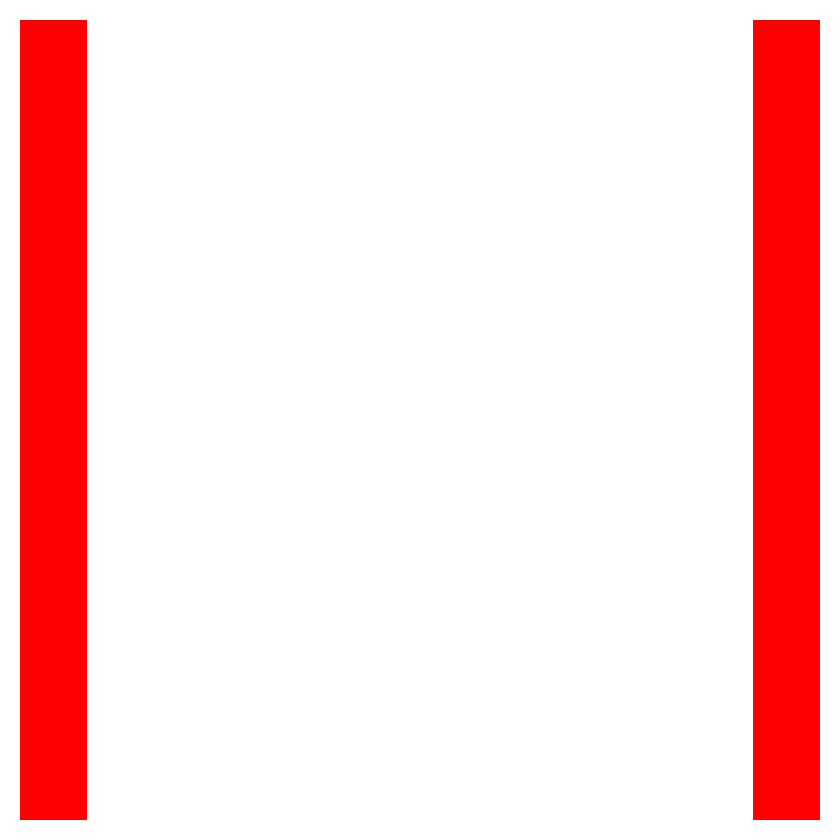

pdf 
  2

pdf 
  2

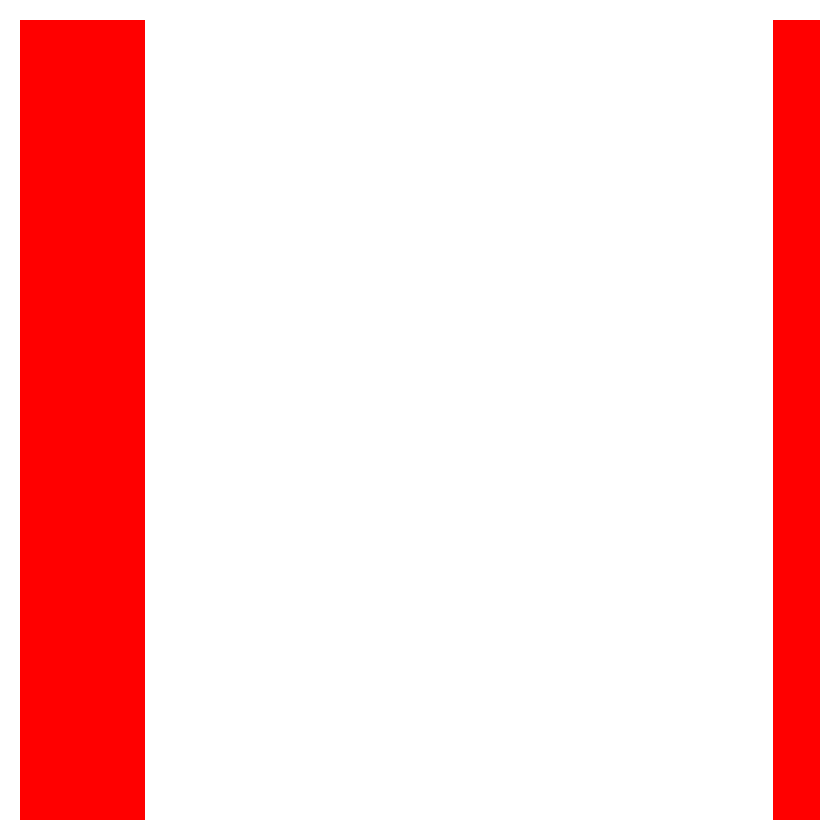

In [43]:
# ---- p-value panel (proximal and distal peaks, plotted separately) ----
makeBinaryPanel <- function(bins, values, threshold = 0.05) {
  betaFrame <- data.frame(bin = bins$globalBin, fc = values < threshold)
  ggplot(betaFrame, aes(x = bin, y = 1, fill = fc)) +
    geom_raster() +
    scale_y_continuous(breaks = NULL, expand = c(0, 0)) +
    scale_x_discrete(breaks = NULL, expand = c(0, 0)) +
    theme_minimal(base_size = 24) +
    scale_fill_manual(values=c("#FFFFFF", "#FF0000")) +
    theme(panel.grid       = element_blank(),
          axis.title       = element_blank(),
          axis.text        = element_blank(),
          legend.position  = "none",
          legend.key.width = unit(0.3, "cm"))
}

myPValProximal <- makeBinaryPanel(proximalBins, proximalBins$binPp)
myPValDistal   <- makeBinaryPanel(distalBins, distalBins$binPp)

myPValProximal
myPValDistal

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_pGrad_proximal.pdf"), width=11, height=3)
print(myPValProximal)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_pGrad_distal.pdf"), width=6, height=3)
print(myPValDistal)
dev.off()

In [48]:
head(mastRes, n = 20)

,index,group_i,beta,beta_se,beta_z,beta_p,beta_LRT,beta_FDR,chrom,start,end,rDex,center,winStart,winEnd,Distance,Distal5kb,Category
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
chr11:123314978:123315279,chr11:123314978:123315279,age,-0.020504161,0.003395381,-6.038840,1.552262e-09,8.995216e-09,0.0001291546,chr11,123314978,123315279,3,123315128,123314128,123316128,207,0,Closing
chr7:142451401:142451702,chr7:142451401:142451702,age,-0.015367127,0.002592248,-5.928107,3.064459e-09,1.453668e-08,0.0001529150,chr7,142451401,142451702,5,142451552,142450552,142452552,453,0,Closing
chr11:12537818:12538119,chr11:12537818:12538119,age,-0.019517903,0.003559648,-5.483099,4.179395e-08,1.612169e-07,0.0005469801,chr11,12537818,12538119,10,12537968,12536968,12538968,2846,0,Closing
chr1:165423257:165423558,chr1:165423257:165423558,age,-0.022485554,0.004124099,-5.452234,4.974090e-08,2.277800e-07,0.0005469801,chr1,165423257,165423558,12,165423408,165422408,165424408,1412,0,Closing
chr16:54286809:54287110,chr16:54286809:54287110,age,-0.021844658,0.004032910,-5.416599,6.074335e-08,2.131797e-07,0.0005469801,chr16,54286809,54287110,14,54286960,54285960,54287960,21,0,Closing
chr18:45619493:45619794,chr18:45619493:45619794,age,-0.021739455,0.004161949,-5.223384,1.756827e-07,6.261471e-07,0.0008252493,chr18,45619493,45619794,28,45619644,45618644,45620644,4011,0,Closing
chr1:210302537:210302838,chr1:210302537:210302838,age,-0.017629785,0.003399200,-5.186451,2.143390e-07,6.795243e-07,0.0008252493,chr1,210302537,210302838,31,210302688,210301688,210303688,844,0,Closing
chr1:9901793:9902094,chr1:9901793:9902094,age,-0.015439401,0.003004027,-5.139568,2.753702e-07,8.109562e-07,0.0008749386,chr1,9901793,9902094,34,9901944,9900944,9902944,1178,0,Closing
chr3:46693581:46693882,chr3:46693581:46693882,age,-0.009513068,0.001856756,-5.123489,2.999325e-07,7.305794e-07,0.0008252493,chr3,46693581,46693882,36,46693732,46692732,46694732,0,0,Closing


In [16]:
# ---- Motif density profile lines (proximal vs. distal vs. combined), split by aging direction ----
# Line-plot panels: mean motif match density by position, for TSS-proximal peaks,
# TSS-distal peaks, and all peaks combined, each with 3 lines: significant closing
# (blue), significant opening (red), and all other peaks (gray). Lines are loess-
# smoothed across position. Position is on the y-axis, matching the Heatmap panel's
# y-axis above.

mastRes$Category <- "Other"
mastRes$Category[mastRes$beta_p > 0.5] <- "No"
mastRes$Category[mastRes$beta_FDR < 0.05 & mastRes$beta_z < 0] <- "Closing"
mastRes$Category[mastRes$beta_FDR < 0.05 & mastRes$beta_z > 0] <- "Opening"

#mastRes <- mastRes[mastRes$Category != "Other",]

catColors <- c(Closing = "#5ab4ac", Opening = "#d8b365", No = "#888888")
LOESS_SPAN <- 0.3

densityProfile <- function(distalFlag = NULL) {
  rows <- if (is.null(distalFlag)) seq_len(nrow(mastRes)) else which(mastRes$Distal5kb == distalFlag)
  do.call(rbind, lapply(names(catColors), function(cat) {
    catRows <- rows[mastRes$Category[rows] == cat]
    if (length(catRows) == 0) return(NULL)
    position   <- seq_len(nNucs)
    rawDensity <- colMeans(motifSortSpace[catRows, , drop = FALSE])
    smoothFit  <- loess(rawDensity ~ position, span = LOESS_SPAN)
    data.frame(position = position,
               density  = predict(smoothFit),
               Category = cat)
  }))
}

proximalDensity <- densityProfile(0)
distalDensity   <- densityProfile(1)
combinedDensity <- densityProfile()

makeDensityPlot <- function(densityDF) {
  ggplot(densityDF, aes(x = density, y = position, color = Category)) +
    geom_path(linewidth = 0.8) +
    scale_color_manual(values = catColors) +
    scale_x_continuous(breaks = c(0, 0.01)) +
    scale_y_continuous(
      breaks = c(0, PEAK_CENTER_FLANK, 2 * PEAK_CENTER_FLANK),
      labels = NULL,
      limits = c(0, nNucs), expand = c(0, 0)) +
    theme_bw(base_size = 24) +
    theme(panel.grid = element_blank(),
          axis.title = element_blank(), legend.position  = "none")
}

proximalDensityPlot <- makeDensityPlot(proximalDensity)
distalDensityPlot   <- makeDensityPlot(distalDensity)
combinedDensityPlot <- makeDensityPlot(combinedDensity)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_proximalDensity.pdf"), width = 2, height = 4.3)
print(proximalDensityPlot)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_distalDensity.pdf"), width = 2, height = 4.3)
print(distalDensityPlot)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/peterPlots/KMCfiddle/{motifName}_combinedDensity.pdf"), width = 2, height = 4.3)
print(combinedDensityPlot)
dev.off()


pdf 
  2

In [50]:
# ---- Fisher's exact test: motif matches at peak center vs. flanking region (per-peak) ----
# Per peak, flags whether it has >=1 motif match in the +/-50bp window centered on
# the peak (the "center" region, 100bp total) and whether it has >=1 motif match in
# the immediately adjacent 50bp on each side of that window (the "flank" region,
# also 100bp total). Compares the fraction of peaks with a hit between the two
# regions, rather than raw bp-level coverage.

CENTER_HALF_WIDTH <- 75  # bp on each side of the peak center

centerCols <- (PEAK_CENTER_FLANK - CENTER_HALF_WIDTH + 1):(PEAK_CENTER_FLANK + CENTER_HALF_WIDTH)
flankCols  <- c((min(centerCols) - CENTER_HALF_WIDTH):(min(centerCols) - 1),
                (max(centerCols) + 1):(max(centerCols) + CENTER_HALF_WIDTH))

centerHasMotif <- rowSums(motifSortSpace[, centerCols, drop = FALSE]) > 0
flankHasMotif  <- rowSums(motifSortSpace[, flankCols,  drop = FALSE]) > 0

nPeaksTotal <- nrow(motifSortSpace)

centerMotifPeaks    <- sum(centerHasMotif)
centerNonMotifPeaks <- nPeaksTotal - centerMotifPeaks

flankMotifPeaks    <- sum(flankHasMotif)
flankNonMotifPeaks <- nPeaksTotal - flankMotifPeaks

motifContingency <- matrix(c(centerMotifPeaks, centerNonMotifPeaks,
                              flankMotifPeaks, flankNonMotifPeaks),
                            nrow = 2, byrow = TRUE,
                            dimnames = list(Region = c("Center_100bp", "Flank_100bp"),
                                            Match  = c("PeakWithMotif", "PeakWithoutMotif")))

motifContingency
motifFisherTest <- fisher.test(motifContingency)
motifFisherTest[1]

,PeakWithMotif,PeakWithoutMotif
Center_100bp,1591,40480
Flank_100bp,1159,40912


$p.value
[1] 5.617139e-17

In [22]:
motifSortSpace

0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
